# Road Accident Predictions with Graph Neural Networks

## 1. Introduction

### 1.1 Motivation

Road traffic accidents impose substantial human and economic costs, estimated at an average of 2.7% of gross domestic product in high-income countries (Wijnen & Stipdonk, 2016). These accidents are, however, highly concentrated. In Delaware, the state examined in this study, 96.5% of road segments record no accident in a given month, whereas the 10% of roads with the highest accident counts account for 70.6% of all recorded accidents (Nippani et al., 2023). Accurate predictions of where accidents are likely to occur would therefore allow transport agencies to direct inspections, enforcement and safety improvements towards the small proportion of the network that accounts for most accidents.

Such predictions are nevertheless challenging. Accidents on an individual road segment are rare events, so predictive models must learn from data in which the absence of accidents dominates. Although human behaviour is a principal cause of crashes, the road environment also contributes by influencing the likelihood of driver errors and violations (Ahmad et al., 2021), and many of the relevant characteristics, such as traffic volume, road layout and surrounding land use, are either unrecorded or available for only a small subset of roads. Furthermore, road segments are not independent: connected segments share traffic flows, junctions and surroundings, so the accident risk of one segment is related to that of its neighbours. A road network is therefore naturally represented as a graph, in which intersections form the nodes and road segments the edges, and graph neural networks (GNN) provide a means of learning directly from this structure.

### 1.2 Objectives

This study evaluates monthly road-level accident prediction in Delaware using the ML4RoadSafety benchmark (Nippani et al., 2023). It considers two tasks: predicting whether an accident occurs on a physical road in a given month and predicting the number of accidents. We select MLP and edge-aware GraphSAGE from the original paper as our reproduction baselines and add two architectures that the original paper did not evaluate: GatedGCN and Graph Transformer. These are established models newly evaluated in this project, rather than architectures proposed by us. Each of the four architectures is trained and evaluated under all four input configurations: baseline, baseline plus OSM context, baseline plus accident history, and baseline plus both OSM context and accident history.

All predictive comparisons retain fixed Node2Vec embeddings (Grover & Leskovec, 2016). The baseline inputs therefore already include structural information about the road network, including in the MLP, which does not perform message passing. Because the project adapts the benchmark's features, embeddings and target aggregation, the experiments constitute a modified reproduction rather than a direct replication of the published results.

### 1.3 Research questions

1. **Road context:** Do additional road and surrounding-area attributes from OSM improve prediction, and which feature groups do the models rely on most?
2. **Accident history:** Does incorporating past accidents on a road and its neighbours improve prediction of next-month accident occurrence and counts?
3. **Model architecture:** Within each of the four input configurations, how do MLP, GraphSAGE, GatedGCN and Graph Transformer differ in monthly accident-occurrence and count prediction?

### 1.4 Main contributions

Building on a modified reproduction of the ML4RoadSafety MLP and GraphSAGE baselines, this study makes four main contributions:

1. **Road-context enrichment:** We develop and validate a pipeline that matches benchmark roads to OSM and constructs road-context features. We evaluate their predictive value and analyse which feature groups the models rely on.
2. **Accident-history features:** We construct temporally valid features summarising previous accidents on each road and its neighbours, then evaluate whether they improve next-month accident-occurrence and count prediction.
3. **Architecture comparison:** We extend the selected MLP and GraphSAGE baselines with GatedGCN and Graph Transformer, neither of which was evaluated in the original paper, and evaluate every architecture under all four input configurations using fixed Node2Vec embeddings and a shared chronological evaluation protocol.
4. **Interactive map tool:** We provide an interactive map for exploring recorded and predicted road risk across the road network.


## 2. Related Work

### 2.1 Accident Prediction and the ML4RoadSafety Benchmark

Road-accident prediction has been studied using statistical, machine-learning and deep-learning approaches. Ma et al. (2017) used negative-binomial and random-effects negative-binomial models to relate expressway crash frequency to road characteristics while examining spatial and temporal correlation. Guerra et al. (2022) compared several regression and machine-learning methods, finding random forests strongest in their setting and annual average daily traffic (AADT) an important predictor. Kashifi et al. (2023) combined convolutional, recurrent and feedforward neural networks for short-term crash prediction using traffic, weather, temporal and crash information. These studies illustrate the range of predictive methods and the importance of the information available to them.

Nippani et al. (2023) introduced ML4RoadSafety, linking accident records, road networks and available traffic data across multiple US states. The original paper evaluates several embedding and neural-network methods, including MLP and GraphSAGE. We select these two as the reproduction baselines for this project and add GatedGCN and Graph Transformer, neither of which was evaluated by Nippani et al. (2023). These two additions extend the original paper's evaluated architecture set; they are established architectures rather than new architectures proposed here. The benchmark provides the data and baseline modelling framework, while this project extends the inputs and architecture comparison and adapts the prediction target to physical-road proxies.

### 2.2 Road Context and Surrounding Land Use

Road attributes and surrounding activities can describe aspects of accident risk that network connectivity alone does not capture. Ahmad et al. (2021) found associations between built-environment contexts, driving errors and crash occurrence. Gao et al. (2024) incorporated road characteristics, points of interest and historical crash data into a graph-based model for daily road-level crash prediction. These studies motivate adding a richer description of roads and their surroundings to the benchmark inputs. In this project, OSM supplies this additional context; RQ1 examines its predictive contribution and which feature groups the fitted models rely on.

### 2.3 Accident History and Neighbouring Roads

Past accidents provide information about how risk varies across roads and over time. Briz-Redón et al. (2022) used previous accidents on road segments and nearby roads to predict daily accident occurrence in Valencia. Temporal history improved prediction in their setting, whereas higher-order spatial lags added little. Gao et al. (2024) also included historical crash information alongside road and surrounding-area attributes. These findings motivate RQ2: whether summaries of previous accidents on a road and its neighbours improve next-month prediction beyond the baseline inputs. Constructing these summaries requires separating records available before the target month from the accidents being predicted.

### 2.4 Graph-Based Prediction and Model Architecture

Graph models represent connections between roads and allow neighbouring locations to exchange information. Huang and Hooi (2022) developed TRAVEL, which incorporates road geometry and connectivity to predict accident occurrence and severity at intersections. Their model outperformed XGBoost and MLP baselines on their city datasets. This supports investigating graph-based prediction, although the benefit of message passing must be evaluated for the task, inputs and dataset under study.

Graph architectures also differ in how they aggregate information. GraphSAGE learns node representations through neighbourhood aggregation (Hamilton et al., 2017). GatedGCN uses learned edge gates to vary neighbouring nodes' contributions (Bresson & Laurent, 2017), while Graph Transformer uses attention to weight information from neighbours (Dwivedi & Bresson, 2020). These alternatives motivate RQ3's comparison of complete architectures with inputs held constant within each of the four configurations. The MLP provides a control without learned message passing, while retaining the same fixed Node2Vec structural embeddings as the graph models.

### 2.5 Positioning of This Study

The literature motivates road context, accident history and graph-based modelling as sources of predictive information. This project examines them within one Delaware benchmark setting: each of the four architectures is evaluated with baseline inputs, with OSM added, with history added and with both additions combined. MLP and GraphSAGE are the selected reproduction baselines from the original paper; GatedGCN and Graph Transformer extend this model set with architectures not evaluated in the original paper. Holding the evaluation protocol and Node2Vec embeddings fixed helps distinguish the effects of input augmentation from differences between architectures. The contribution is the construction and evaluation of these comparisons within the project's setting, rather than the introduction of OSM context, accident history or the architectures themselves. Comparing complete architectures establishes their relative performance under the chosen conditions; it does not isolate the causal effect of gating or attention alone.


## 3. Dataset, Exploratory Analysis and Preprocessing

### 3.1 Original Benchmark Data

#### 3.1.1 Dataset Scope and Quality

**ML4RoadSafety dataset**

ML4RoadSafety is a public road-safety dataset constructed from official accident reports across eight US states, comprising more than nine million records in the full collection (Nippani et al., 2023). It links accident locations and dates to road networks derived from OSM. Each state is represented as a directed graph, where nodes correspond to intersections and edges represent road segments. The dataset includes node-level structural and weather information, such as node degrees, coordinates, temperature and precipitation, as well as edge-level attributes, including road length, road category and AADT, where available. Accident records are associated with road-network edges and can be used to study monthly accident counts and occurrence. The dataset is available through [Harvard Dataverse](https://doi.org/10.7910/DVN/V71K5R).

In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
# Use Google Drive in Colab, or the local repository otherwise.
import os
import sys
from pathlib import Path

if 'google.colab' in sys.modules:
    from google.colab import drive
    drive.mount('/content/gdrive')
    PROJECT_DIR = Path(os.environ.get(
        'CS5284_PROJECT_DIR', '/content/gdrive/MyDrive/cs5284_project'))
else:
    configured = os.environ.get('CS5284_PROJECT_DIR')
    if configured:
        PROJECT_DIR = Path(configured).expanduser()
    else:
        PROJECT_DIR = next(
            (p for p in (Path.cwd(), *Path.cwd().parents)
             if (p / 'src' / 'eda.py').is_file()), None)
        if PROJECT_DIR is None:
            raise FileNotFoundError('Open this notebook inside the repository or set CS5284_PROJECT_DIR.')

PROJECT_DIR = PROJECT_DIR.resolve()
if not (PROJECT_DIR / 'src' / 'eda.py').is_file():
    raise FileNotFoundError(f'Place the repository (including src/eda.py) in {PROJECT_DIR}, or update PROJECT_DIR.')
os.chdir(PROJECT_DIR)
if str(PROJECT_DIR) not in sys.path:
    sys.path.insert(0, str(PROJECT_DIR))
DATA_DIR = Path(os.environ.get('CS5284_DATA_DIR', str(PROJECT_DIR / 'data'))).expanduser().resolve()
os.environ['CS5284_PROJECT_DIR'] = str(PROJECT_DIR)
os.environ['CS5284_DATA_DIR'] = str(DATA_DIR)
print(f'Project: {PROJECT_DIR}')
print(f'Data: {DATA_DIR}')


Project: C:\Users\aaron\OneDrive\Desktop\NUS\Masters of Computing (AI Specialisation)\Sem 4\CS5284\Project\CS5284_GML
Data: C:\Users\aaron\OneDrive\Desktop\NUS\Masters of Computing (AI Specialisation)\Sem 4\CS5284\Project\CS5284_GML\data


In [3]:
from IPython.display import display
import matplotlib.pyplot as plt
from src.reporting import apply_report_style
apply_report_style()
from src.eda import (
    load_data, dataset_summary, split_summary, audit_data,
    accident_distribution, concentration, historical_persistence,
    plot_monthly_accidents, plot_risk_profile,
)

STATES = ('DE',)
data = load_data(DATA_DIR, states=STATES)
summary = dataset_summary(data)
audit = audit_data(data)
distribution = accident_distribution(data)
concentration_table = concentration(data)

This study focuses on the state of Delaware, covering the period spanning January 2009 to September 2022. Descriptive statistics found some discrepancies between the dataset that we used and the ones reported in the original paper. The differences were likely due to rounding errors or minor enough to ignore. In general, we observed that Delaware has 49,023 nodes and 116,196 edges, representing intersections and directed road segments, with an average monthly accidents of 2,777 accidents per month. Data quality audit was also performed to check for missing, duplicated, or abnormal data on accident records and node information. There were no invalid accident counts or duplicated entries. However, some weather and traffic data were missing. The comparison between some statistics reported in the paper and what we found in the data is summarised in the table below.

Our audit identified issues with temporal coverage and label directionality. The files contain 165 usable months from January 2009 to September 2022. October has only 23 recorded accidents, while November and December have none; these months are excluded from evaluation. Low counts in early 2009 may also reflect incomplete reporting. During training (2009–2012), 15,057 of the graph’s 50,944 bidirectional endpoint pairs have recorded accidents, all assigned to one direction per pair. Of these accidents, 96.65% are attached to the lower-index-to-higher-index edge, suggesting that the labels do not reliably distinguish travel direction.

Unlike the benchmark’s directed-edge prediction task (Nippani et al., 2023), we sum monthly counts across edges with the same unordered endpoints to form a **physical-road proxy**, while retaining a directed message-passing graph. Each road-month is one proxy observed in one month: classification predicts whether any accident occurs, and regression predicts the count, including zeros. Together with changes to features, embeddings and evaluation, it makes our study a modified reproduction rather than a direct replication.

In [4]:
import pandas as pd

# The published values below are transcribed from Nippani et al. (2023), Table 1.
metrics = [
    ('Period', 'Period', '2009–2022', 'text'),
    ('Nodes', 'Nodes', '49,023', 'int'),
    ('Directed road segments', 'Directed edges', '116,196', 'int'),
    ('Average accidents per month', 'Accidents/month', '2,763', 'int'),
    ('Average outgoing degree', 'Mean degree', '2.4', 'decimal'),
    ('Maximum outgoing degree', 'Max degree', '6', 'int'),
    ('Average directed segment length (m)', 'Mean length (m)', '213', 'int'),
    ('Traffic coverage: physical-road proxies (%, any year)', 'Traffic coverage (%)', '3.14%', 'percent'),
]

def format_value(value, kind):
    if kind == 'text':
        return str(value)
    if kind == 'int':
        return f'{value:,.0f}'
    if kind == 'decimal':
        return f'{value:.1f}'
    return f'{value:.2f}%'

rows = []
for label, key, paper_de, kind in metrics:
    row = {'Measure': label}
    for state, paper in [('Delaware', paper_de)]:
        if state in summary.index:
            row[f'{state}: this analysis'] = format_value(summary.loc[state, key], kind)
            row[f'{state}: paper'] = paper
    rows.append(row)
comparison = pd.DataFrame(rows).set_index('Measure')
display(comparison)

,Delaware: this analysis,Delaware: paper
Measure,,
Period,2009-01 to 2022-09,2009–2022
Nodes,"49,023","49,023"
Directed road segments,"116,196","116,196"
Average accidents per month,"2,777","2,763"
Average outgoing degree,2.4,2.4
Maximum outgoing degree,6,6
Average directed segment length (m),213,213
"Traffic coverage: physical-road proxies (%, any year)",3.16%,3.14%


#### 3.1.2 Road-Network Structure

**Graph Laplacian analysis**

We analyse the road network using the symmetric normalized Laplacian, $L_{\mathrm{sym}} = I-D^{-1/2}AD^{-1/2}$. A connection in either direction is treated as an undirected, unweighted edge; reciprocal and duplicate edges are collapsed and self-loops removed. The graph contains 75 connected components, including 18 isolated intersections. The largest component contains 48,727 of 49,023 intersections, or approximately 99.4%. We focus the spectral analysis on this component to examine connectivity within the main road network.

Its second-smallest normalized Laplacian eigenvalue is approximately $2.37 \times 10^{-6}$, suggesting a loosely connected partition within the main network. The map shows the corresponding eigenvector where it shows a gradual pattern from north to south. This suggests that the road network’s connectivity varies across Delaware: intersections in the north tend to have similar eigenvector values, as do those in the south, with central Delaware forming a gradual transition between them.

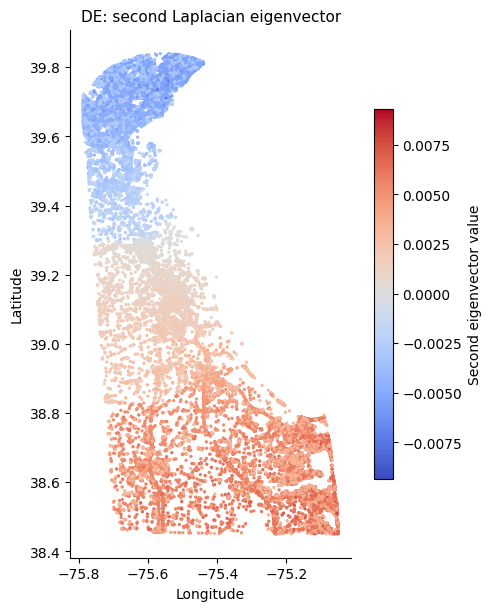

In [5]:
from src.eda import graph_laplacian_eda

laplacian_summary, laplacian_figures = graph_laplacian_eda(data)
display(laplacian_figures[0])
plt.close(laplacian_figures[0])

#### 3.1.3 Accident Distribution over Time

**Recorded accidents over time**

The figure below shows a time series plot of the recorded accidents over time for Delaware. The plots segment the periods according to the training, validation, and test sets used in the original paper from Nippani et al. (2023). As Delaware's data starts from an earlier date, the recorded accidents began much earlier in 2009. Recorded counts rose sharply between 2009 and 2010, remained relatively stable through 2012, and generally increased in subsequent years. However, it experienced a significant drop in accidents around April 2020. This coincides with the lockdown orders placed during the COVID-19 pandemic (Castillo et al., 2020). The accidents slowly recovered to their previous values after the lockdown period.

Furthermore, we also analysed the potential of any seasonality in the data. We observed that there is a consistent seasonality where the mean recorded accidents are lower at the start of the year and slowly increase from January to December. The last quarter of the year usually has a higher mean recorded accidents. This might be attributed to increased travelling due to the festive season at the end of the year.

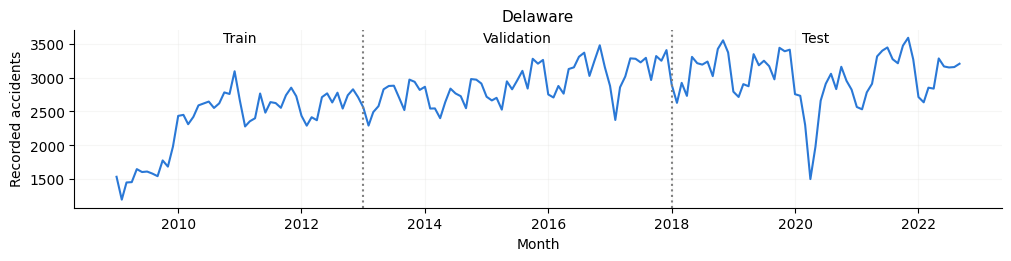

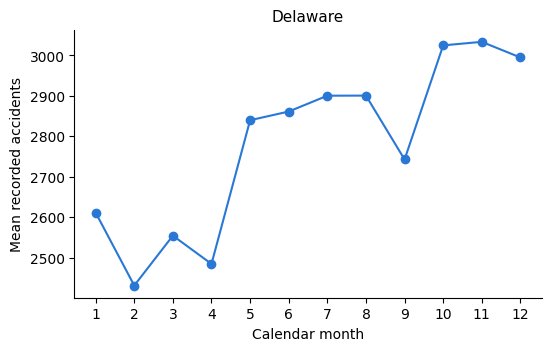

In [6]:
from src.eda import plot_seasonality

fig = plot_monthly_accidents(data)
plt.show()

fig = plot_seasonality(data)
plt.show()


#### 3.1.4 Accident Sparsity and Concentration

Accident counts are sparse at the road-month level. In Delaware, 96.52% of roads recorded no accidents in a given month. Positive counts are therefore concentrated in a small proportion of road-months. Accidents are also unevenly distributed across roads. Over the full observation period, the 10% of roads with the highest recorded counts accounted for 70.6% of accidents in Delaware. These patterns indicate that accidents are highly sparse and concentrated in a small proportion of roads, and may suggest that prediction tasks should use evaluation metrics that account for class imbalance and assess how well models identify higher-risk roads.

,Road-months,Zero accidents (%),Mean count
State,,,
Delaware,"10,766,580",96.52,0.0426


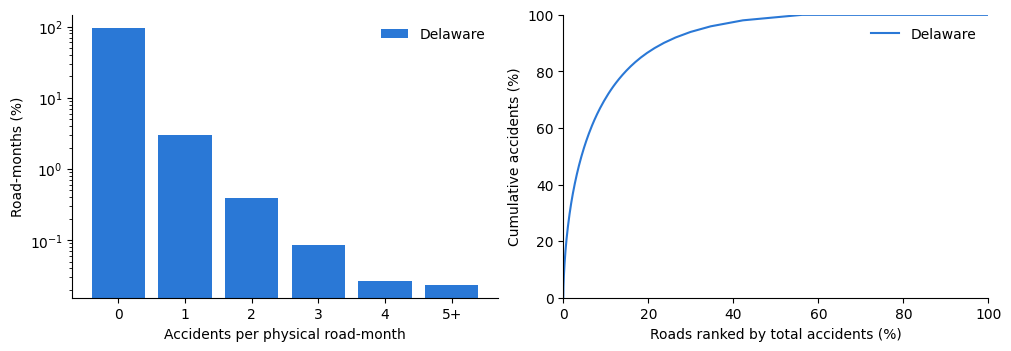

In [8]:
display(distribution[['Road-months', 'Zero accidents (%)', 'Mean count']].style.format({
    'Road-months': '{:,.0f}', 'Zero accidents (%)': '{:.2f}', 'Mean count': '{:.4f}',
}))
fig = plot_risk_profile(data)
plt.show()


#### 3.1.5 Road Characteristics and Spatial Patterns

**Road characteristics, traffic volume, and accidents**

We examined the relationships between road length, road type, AADT, and recorded accidents. For the road-length and AADT plots, observations were grouped into five quantiles for better visibility, while Spearman correlations were calculated using the ungrouped observations. Road length had a Spearman correlation of 0.258 with mean accidents per road-month. This indicates a positive relationship: longer roads tended to record more accidents per month. Longer segments also cover more distance, so they provide a greater opportunity for accidents to occur. Among the road types shown, motorways had the highest mean accident count per road-month, while residential roads had the lowest. This comparison includes roads assigned a single road type and categories containing at least 100 roads. AADT had a Spearman correlation of 0.111 with the mean monthly accident count in the same year, indicating a weak positive relationship. Roads carrying more traffic tended to record more accidents, consistent with a greater number of vehicles being exposed to accident risk. Together, these findings suggest that road length, road type and traffic volume provide useful context for understanding differences in recorded accident counts across roads.

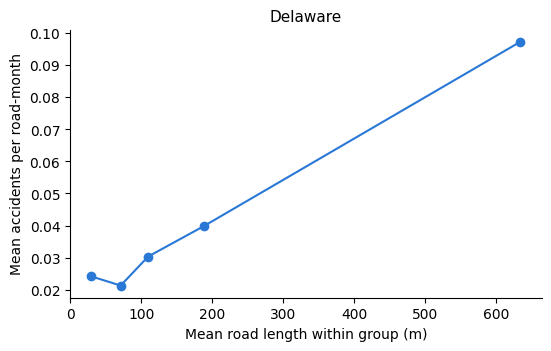

,Roads,Spearman correlation
State,,
Delaware,"65,252",0.258


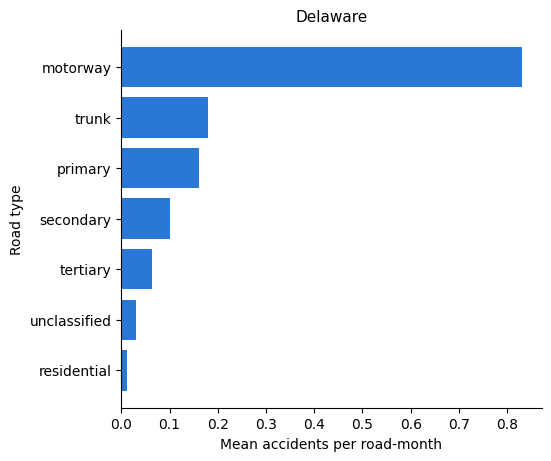

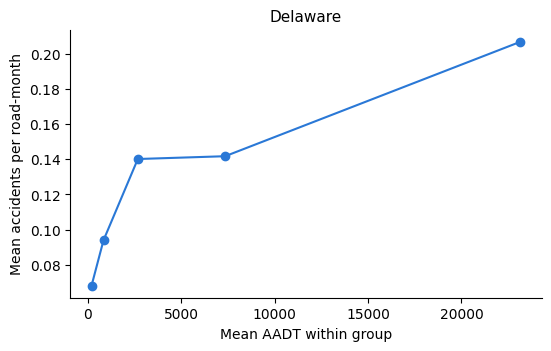

,Observed road-years,Spearman correlation
State,,
Delaware,"10,481",0.111


In [9]:
import numpy as np
import pandas as pd
from src.eda import (plot_length_risk, plot_road_type_risk, traffic_accident_association,
                     plot_traffic_risk, _feature_series, _risk, STATE_NAMES)

# Figure 4: road length and full-period accident counts.
fig = plot_length_risk(data, training_only=False)
plt.show()
length_stats = []
for state, state_data in data.items():
    lengths = _feature_series(state_data.edge_features['length'], state_data.n_nodes, physical=True)
    pairs = pd.DataFrame({'Length (m)': lengths.reindex(state_data.roads),
                          'Mean monthly accidents': _risk(state_data, training_only=False)}).dropna()
    pairs = pairs[pairs['Length (m)'] > 0]
    length_stats.append({'State': STATE_NAMES[state], 'Roads': len(pairs),
                         'Spearman correlation': pairs.corr(method='spearman').iloc[0, 1]})
display(pd.DataFrame(length_stats).set_index('State').style.format(
    {'Roads': '{:,.0f}', 'Spearman correlation': '{:.3f}'}))

# Figure 5: recorded road type and full-period accident counts.
fig = plot_road_type_risk(data, training_only=False)
plt.show()

# Figure 6: observed annual AADT and accident counts from the same year.
traffic_observations = traffic_accident_association(data, training_only=False)
fig, traffic_stats = plot_traffic_risk(traffic_observations)
plt.show()
display(traffic_stats.style.format({'Observed road-years': '{:,.0f}', 'Spearman correlation': '{:.3f}'}))


**Spatial exploration of recorded accidents**

We also inspect the spatial distribution of road accidents visually through an interactive map below. In Delaware, accidents are concentrated in the northern part of the state, particularly around Wilmington. Linear patterns extend southward towards central and southern Delaware, including the area around Dover. These patterns may correspond to major expressways connecting to different parts of the state. This north–south pattern also resembles the gradual change in eigenvector values observed in the graph Laplacian analysis, which reflects the connectivity of the road network. The interactive map will also show the predicted model results from the later sections.

In [4]:
from src.visualization.risk_map import show_risk_map
from IPython.display import FileLink, display

SHOW_INTERACTIVE_MAPS = True
MAP_MAX_ROADS = None  # Display every road in each state network.
MAP_OUTPUT_DIR = PROJECT_DIR / 'results' / 'visualizations'
if SHOW_INTERACTIVE_MAPS:
    eda_map_path = show_risk_map(
        PROJECT_DIR, max_roads=MAP_MAX_ROADS, mode='eda',
        data_dir=DATA_DIR, results_dir=PROJECT_DIR / 'results', state_codes=STATES,
        output_path=MAP_OUTPUT_DIR / 'road_safety_full_eda.html',
    )
    display(FileLink(str(eda_map_path), result_html_prefix="Open standalone map: "))


Saved standalone application: C:\Users\aaron\OneDrive\Desktop\NUS\Masters of Computing (AI Specialisation)\Sem 4\CS5284\Project\CS5284_GML\results\visualizations\road_safety_full_eda.html


C:\Users\aaron\OneDrive\Desktop\NUS\Masters of Computing (AI Specialisation)\Sem 4\CS5284\Project\CS5284_GML\results\visualizations\road_safety_full_eda.html

### 3.2 OpenStreetMap Road Context



#### 3.2.1 Data Source and Motivation

The benchmark's road inputs consist only of road-type indicators and segment length, together with annual average daily traffic (AADT), which is observed for only 3.16% of physical roads in Delaware. Its road graph was itself derived from OSM, but the descriptive attributes that OSM records for many of these roads, such as speed limits, lane counts, junction controls and nearby amenities, were not retained.

This subsection describes how these attributes were extracted, matched to the benchmark's roads, cleaned and encoded, and examines which of them are associated with accident rates independently of any model. Their effect on prediction (RQ1) is reported in Section 5.3.

The OSM data were taken from a dated extract of Delaware published by Geofabrik, a snapshot of 18 October 2026 distributed under the Open Database Licence (Geofabrik GmbH & OpenStreetMap contributors, 2026). A single dated snapshot was used rather than one extract per accident year, because processing a series of extracts was beyond the computational and storage resources available to this project; a dated file also allows the pipeline to be reproduced exactly. The consequences of this choice are discussed in Section 6.1. The extract was read with the OSMnx library (Boeing, 2025) and converted into three tables: road segments with their recorded attributes, point features that control traffic (signals, stop and give-way signs, pedestrian crossings and traffic-calming devices), and points of interest such as schools, bus stops, food outlets and parking. Before matching, the benchmark's node coordinates were corrected, because the latitude and longitude columns in the released node files are labelled the wrong way round for all 49,023 Delaware intersections, and the node order of every road was verified against its recorded length.

#### 3.2.2 Road Matching and Validation

The benchmark's road graph was built from an older version of OSM, and the map has changed since then. Only 88.8% of the benchmark's intersection identifiers still exist in the current extract, and the current network contains about 10% more intersections and roads. For each benchmark road, we therefore had to find the corresponding road in the current map.

Matching was done in two steps. First, each benchmark intersection was linked to the OSM intersection with the same identifier if the two lie within 25 m of each other, and otherwise to the nearest OSM intersection within 20 m. Second, each benchmark road was linked to an OSM road by the first of three rules that applies: an exact match, which is an OSM road with the same two end points; a reverse match, with the same end points in the opposite order; or a nearest match, which is the closest OSM road whose midpoint lies within 30 m and whose length is 0.6 to 1.6 times the benchmark length.

Linking each road to the closest candidate within a set distance is a common way of combining two maps of the same area (Goodchild & Hunter, 1997). We set the distance limits well above the usual positional error of OSM. Haklay (2010) found that roads in OSM lie on average about 6 m from their position in official survey maps, so limits of 20 to 30 m ensure that a road is not left unmatched merely because the two maps place it a few metres apart. The length condition is our own choice rather than a published value. It prevents a short side street from being matched to a long main road that runs next to it.

The table below summarises the results. Overall, 89.6% of the 116,196 directed roads were matched, and 85.1% were exact matches. We checked the matches in three ways. First, because the matching never uses road type, road type provides an independent check. The benchmark's road type agrees with that of the matched OSM road for 94.6% of exact matches and 84.6% of nearest matches, and most disagreements are between similar classes, such as primary and trunk roads. Second, exact matches have almost identical lengths in both sources, with a median length ratio of 1.00. Third, the result is not sensitive to the chosen limits. With distance limits from 10 to 75 m and length limits from 0.8–1.25 to 0.5–2, the match rate stays between 87.0% and 92.1%.

Two groups of roads are small in number but account for many accidents. Roads that could only be matched by the third rule, to the nearest OSM road within 30 m, make up 4.0% of roads but 14.9% of accidents. These are likely to be mainly major roads. OSM often draws a major road as two separate one-way roads, one for each direction, whereas the benchmark contains a single road, so the end points in the two maps differ and only the distance rule finds a match. Roads with no match at all make up 10.4% of roads but 15.7% of accidents. Removing them would discard about one in six of the accidents the model must predict, so they are kept, with an indicator telling the model that the road has no OSM information.

| Matching tier | Directed roads | Share of roads | Share of accidents | Road type agrees | Length ratio, median [5th, 95th percentile] |
|---|---|---|---|---|---|
| Exact (same end nodes) | 98,855 | 85.1% | 68.9% | 94.6% | 1.00 [0.97, 1.04] |
| Reverse (end nodes swapped) | 584 | 0.5% | 0.4% | 90.6% | 1.00 [0.87, 1.15] |
| Nearest (within 30 m, ratio 0.6–1.6) | 4,636 | 4.0% | 14.9% | 84.6% | 0.94 [0.64, 1.52] |
| Matched in total | 104,075 | 89.6% | 84.3% | | |
| Not matched | 12,121 | 10.4% | 15.7% | | |
| All benchmark roads | 116,196 | 100.0% | 100.0% | | |

*Outcome and validation of matching the benchmark's directed roads to OSM in Delaware. Road-type agreement compares the benchmark's road type with that of the matched OSM road, which the matching procedure does not use. Source: `notebooks/osm_features_and_eda.ipynb`, Stages 8 and 9.1.*



#### 3.2.3 Attribute Availability, Cleaning and Missing Values



OSM attributes are entered by volunteers as free text, so each attribute was converted to a numerical value using fixed rules. Where several values were recorded for one road segment, the highest value was kept; for example, "25 mph; 35 mph" became 35 mph. Values recorded only in words, such as "none", were treated as missing, and a road whose OSM segments recorded different surfaces was classified as mixed.

Several attributes are missing for most roads. The speed limit is recorded for only 13.9% of roads, but those roads carry 43.8% of accidents, because major roads are mapped more thoroughly than residential streets. A missing value therefore indicates that the attribute was not mapped rather than that its value is zero, and whether a value is recorded is itself informative. Each missing value was replaced by the mean of the feature, and an indicator was added to record whether the value was recorded in OSM or filled with the mean.

We also tested whether the three most incomplete attributes, the speed limit, the number of lanes and the surface, could instead be estimated from neighbouring roads of the same road type. Only the speed limit met the acceptance criteria, and even then 88.6% of roads with a missing speed limit have no neighbour with a recorded value, so their estimate would come from road type alone, which the model already receives as an input. The estimated values were therefore not used in the model. The method and validation results are given in Appendix A.2.

#### 3.2.4 Feature Construction and Encoding

From the matched data, 58 features were constructed in five groups, which are shown in the table below with the reason for including each group. Each feature was attached to a road in one of four ways. Road attributes were taken from the matched OSM road. Control points were assigned to a road if they lie on its start or end junction, and control points between junctions were assigned to the nearest road within 15 m. Nearby places were counted within 100, 250, 500 and 1,000 m of the road's midpoint, together with the distance to the nearest place of each kind. Road shape was computed from the benchmark's own road geometry. Road type and length, which the benchmark already contains, were not duplicated. Appendix A.1 lists every feature with its definition, OSM source and encoding.

| Group | Features | Rationale | Roads with a value |
|---|---|---|---|
| Road character | speed limit, number of lanes, surface, bridge, tunnel | Speed and road width shape traffic volume and the frequency and severity of conflicts | 13–17% (speed, lanes, surface); 90% (bridge, tunnel) |
| Intersection control | signals, stop signs, give-way signs and crossings at the road's ends and between junctions; roundabouts; traffic calming | Accidents concentrate at junctions, and the form of control changes how conflicting movements are resolved | 90% |
| Cycle, pedestrian and lighting | cycle lane, sidewalk, street lighting | Indicate the presence of vulnerable road users and visibility at night | 1–2% |
| Nearby places | counts of schools, bus stops, food outlets, bars, parking, crossings and signals within 100–1,000 m, and distance to the nearest of each | Proxies for pedestrian activity, turning traffic and urban density; available for every road | 100% |
| Road shape | curvature ratio (length divided by straight-line distance) | Bends reduce sight distance | 99% |

*OSM feature groups for Delaware. Coverage is the share of the 116,196 directed roads with a value. A complete list is given in Appendix Table A1.*

The features were encoded in the same way as the benchmark's own road features. Counts and distances, which are highly skewed, were log-transformed, continuous features were standardised, and the surface was one-hot encoded. Together with the missing-value indicators described in Section 3.2.3 and an indicator for roads without an OSM match, this gives 70 encoded columns for each directed road.

#### 3.2.5 Associations with Accident Rates

Before adding the OSM features to a model, we examined whether they are associated with accident rates. Comparing raw accident counts would be misleading, because long roads and major roads have more accidents regardless of their other features (Section 3.1.5). Each road was therefore compared with similar roads. Roads were grouped by road type and length band, and the accident rate per kilometre per year was calculated for each group. A road's expected number of accidents was then its group's rate multiplied by its length and the number of years observed. For each feature, the rate ratio is the number of accidents observed on roads with that feature divided by the number expected. A ratio of 2 means twice as many accidents as on similar roads, and a ratio of 0.5 means half as many.

Features that tend to occur together can all appear risky for the same reason. A busy street, for example, typically has traffic signals, pedestrian crossings and restaurants, so all three may show high ratios even if only the busy setting is responsible. We therefore also fitted a Poisson regression, a standard model for count data, that includes all features together with road type and length. It estimates the rate ratio of each feature with the other features held fixed. The table below reports both analyses for selected features.

| Feature (level) | Rate ratio relative to similar roads [95% CI] | Roads where known | Clear in the joint regression |
|---|---|---|---|
| Food outlets within 250 m (6 or more) | 2.44 [2.28, 2.62] | 100% | Yes |
| Traffic signals within 250 m (6 or more) | 2.01 [1.90, 2.12] | 100% | Yes |
| Signal at a road end | 1.85 [1.78, 1.93] | 90% | Yes |
| Number of lanes (4 or more) | 1.70 [1.54, 1.87] | 15% | Yes |
| Stop sign at a road end | 1.68 [1.54, 1.84] | 90% | Yes |
| Stop signs between junctions (2 or more) | 0.57 [0.47, 0.70] | 90% | Yes |
| Roundabout | 0.29 [0.20, 0.41] | 90% | Yes, but weaker and not confirmed in the training years |
| Signals between junctions (2 or more) | 3.41 [1.75, 6.63] | 90% | No: 1.69 [0.90, 3.20] |
| Crossings between junctions (2 or more) | 2.63 [2.30, 3.01] | 90% | No: 1.23 [1.08, 1.40] |

*Accident rates on roads with selected OSM features relative to similar roads in Delaware, 2009–2022. The interval accounts for accidents clustering on a few roads. An effect is counted as clear only if its interval excludes 1 and the ratio lies outside 0.8–1.25. The final column reports whether the effect remains clear, in the same direction, in the joint Poisson regression, which includes road type and an exposure offset and uses robust standard errors (MacKinnon & White, 1985). Source: `notebooks/osm_features_and_eda.ipynb`, Stage 12.*

The results lead to three conclusions. First, roads in busy surroundings have markedly more accidents. Roads with many food outlets or traffic signals nearby, or with a signal or stop sign at either end, have between 1.7 and 2.4 times the accidents of similar roads, and these effects remain clear in the joint regression. Second, the two largest single-feature effects, for signals and crossings between junctions, largely disappear in the joint regression, which suggests that these features mark busy areas rather than adding risk of their own. Third, roundabouts and repeated stop signs between junctions are associated with fewer accidents, consistent with their role in slowing traffic. The same patterns are observed when the analysis is restricted to the training years, 2009–2012.

These results identify features that are associated with higher or lower accident rates; they do not establish that the features cause accidents. A road with many restaurants nearby, for example, is likely to have more accidents because it carries heavy traffic rather than because of the restaurants themselves. For prediction, however, this distinction is not essential: a feature that reliably identifies high-accident roads is useful to the model regardless of the underlying cause, which motivates the inclusion of the OSM features in the model.

### 3.3 Engineered Accident-History Features



#### 3.3.1 Motivation and Feature Construction

Road type, length and network position describe relatively stable properties of a road. Weather and traffic provide time-varying context, but these inputs do not capture the sequence of crashes on a road in the months leading up to a forecast. The preceding analysis showed that roads with a recent crash were more likely to record another. We therefore summarise monthly crash records on each road and its neighbours to test whether this history improves forecasts of next-month crash occurrence and count.

**Feature construction**
For a prediction in month $t$, only earlier months enter the ten raw features. These fall into three groups.

**1. Own-road history (six features).** The previous month's count $c_{r,t-1}$ captures recent activity. The count twelve months earlier, $c_{r,t-12}$, provides a comparison with the same calendar month of the previous year. Three rolling means describe how the recent monthly crash count compares across a quarter, half a year and a full year. The sixth feature measures how regularly crashes recur over the year.

$$\mathrm{Mean}_{k}(r,t)=\frac{c_{r,t-1}+\cdots+c_{r,t-k}}{k},\qquad k\in\{3,6,12\}.$$

$$\mathrm{Recurrence}_{12}(r,t)=\frac{\text{number of months with at least one crash in the preceding 12 months}}{12}.$$

The annual mean gives equal weight to every crash. Recurrence counts each crash-positive month once, so it distinguishes crashes concentrated in one month from the same total spread across the year. Each lag requires its source month to be available, and each rolling measure requires its full window.

**2. Neighbouring-road history (three features).** Roads sharing either endpoint with the target road provide local context when the road itself has little recent history. We count each distinct neighbouring road once and exclude the target road. For roads with at least one neighbour, we compute

$$\mathrm{NeighbourMean}(x)=\frac{\text{sum of }x\text{ across neighbouring roads}}{\text{number of neighbouring roads}}.$$

Applying this average first to each neighbour's previous-month count and then to its three-month rolling mean gives two features. Averaging makes the scale interpretable as crashes per neighbouring road. The third feature, the number of neighbours, distinguishes an isolated road from a connected road whose neighbours recorded no crashes. Both have zero neighbour averages when the source window is available. An unavailable window is recorded as missing.

**3. Source coverage (one feature).** We count how many of the preceding twelve months have usable source records. A month with usable records counts towards coverage even when the road recorded zero crashes. This distinguishes a fully observed quiet year from a year with incomplete records.



#### 3.3.2 Feature Availability and Warm-Up

Before fitting the models, we examine how often these features are available and how much information the different history windows share. The feature profiles cover the 48 model-training months from 2009–2012 on the 65,252 physical-road proxies. Outcome associations use only 2010–2012 targets after a 12-month history warm-up, so validation and test labels do not inform these observations.



#### 3.3.3 Feature Distributions and Redundancy

The figures below compare the share of observed road-months with zero history, the distribution of positive values and the rank correlations among own-road measures. The correlations use a fixed random sample of 100,000 eligible training road-months.

The three-month mean is positive in only 7.3% of observed road-months for the road itself, compared with 24.1% for its neighbours. Extending the own-road window to twelve months also captures more crash history, but 81.4% of observed annual means are still zero. A short own-road window therefore assigns the same value to most roads. Neighbour history gives the model another way to distinguish some of those roads.

The six- and twelve-month means have a Spearman correlation of 0.818. The annual mean and annual recurrence have a correlation of 1.000 at the displayed precision. Although the latter two measure different aspects of history, they rank these training observations almost identically. This overlap limits how precisely a change in model performance can be attributed to an individual history window.

Source coverage: 166 months have rows; 165 are usable through 2022-09 under the current cutoff.
2022-10 recorded count: 23; 2022-11/12 have rows: False.
Training direction audit: 50,944 two-way pairs; 15,057 with crashes, 15,057 with records on one orientation only.
No two-way positive road-month has crashes on both orientations (0/49,329); 96.65% of two-way counts are on lower-index-to-higher-index edges.


Feature,Missing (%),Zero (%),Median,P90,P99
Own-road lag 1 month,2.1,97.0,0.0,0.000,1.000
Own-road mean 3 months,6.3,92.7,0.0,0.000,0.667
Own-road mean 12 months,25.0,81.4,0.0,0.083,0.583
"Own-road nonzero fraction, 12 months",25.0,81.4,0.0,0.083,0.417
Neighbour lag 1 month mean,2.1,88.2,0.0,0.167,0.500
Neighbour mean 3 months,6.3,75.9,0.0,0.133,0.444
Number of neighbours,0.0,0.1,4.0,6.000,6.000


Mean 3m,Mean 6m,Mean 12m,Nonzero fraction 12m
1.000,0.785,0.645,0.645
0.785,1.000,0.818,0.818
0.645,0.818,1.000,1.000
0.645,0.818,1.000,1.000


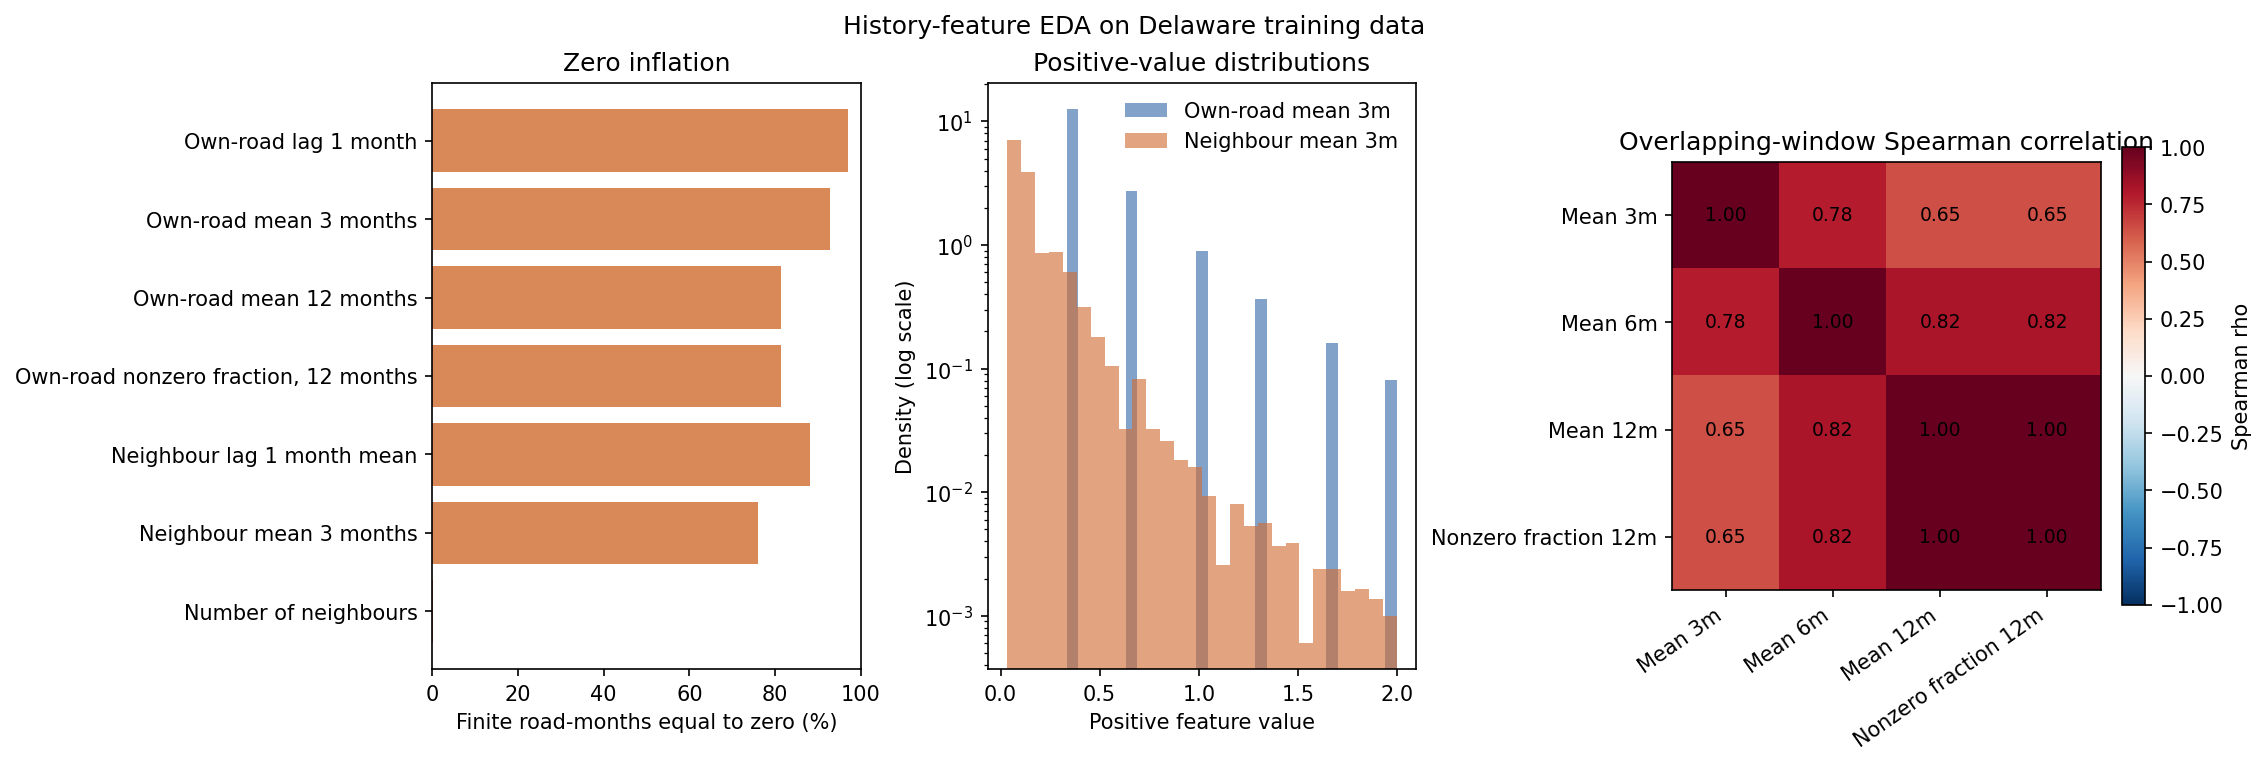

In [31]:
import numpy as np
from src.data.history import build_physical_features
from src.history.report import (
    load_training_road_counts, history_feature_profile,
    history_window_correlations, plot_history_profile,
)

counts, usable_months, neighbours, edge_to_road = load_training_road_counts(DATA_DIR / "DE")
train_features = np.stack([
    build_physical_features(counts, usable_months, month, neighbours)
    for month in range(len(counts))
])
profile = history_feature_profile(train_features)
correlation = history_window_correlations(train_features)
display(profile, correlation.round(3))
plot_history_profile(train_features, profile, correlation)
plt.show()

#### 3.3.4 Own-Road and Neighbour History and Subsequent Accidents
Using Delaware training targets from 2010–2012, after a twelve-month history warm-up, we examined whether past accidents were associated with subsequent accident occurrence. We grouped road-months by whether the road had recorded an accident in the preceding one, three, six or twelve months, then calculated the proportion with an accident in the current month. This proportion was 21.81% for roads with an accident in the previous month, compared with 2.44% for those without one. The same pattern held across longer windows, consistent with Briz-Redón et al. (2022).

Both next-month accident incidence and mean crash count also increased with the number of crashes in the preceding quarter. Comparing roads with no crashes against those with six or more, incidence rose from 2.04% to 75.80%, while the mean count rose from 0.0221 to 2.1551. However, the latter group contained only 2,657 road-months, compared with more than 2.16 million in the crash-free group.

Among roads with a crash-free quarter, next-month incidence was 1.15% when their neighbours also had no recent crashes and 5.17% when at least one neighbour had a recent crash. Neighbour history therefore distinguishes roads with otherwise identical zero own-road history. Together, these training-period associations motivate evaluating own-road and neighbour history as predictive features on held-out months

In [4]:
from src.eda import history_window_risk
history_windows = history_window_risk(data)
display(history_windows.style.format({'Road-months': '{:,.0f}', 'Accident road-months': '{:,.0f}',
                                     'Next-month accident (%)': '{:.2f}'}))

,State,Prior months,History,Road-months,Accident road-months,Next-month accident (%)
0,Delaware,1,None,"2,975,238","72,470",2.44
1,Delaware,1,One or more,"91,606","19,981",21.81
2,Delaware,3,None,"2,721,525","51,794",1.90
3,Delaware,3,One or more,"214,815","38,333",17.84
4,Delaware,6,None,"2,411,285","36,357",1.51
5,Delaware,6,One or more,"329,299","49,749",15.11
6,Delaware,12,None,"1,911,333","21,990",1.15
7,Delaware,12,One or more,"437,739","55,553",12.69


Prior 3-month accidents,Road-months,Next-month incidence (%),Mean next-month count
0,2163898,2.0446,0.0221
1,136650,12.5196,0.1475
2,30091,24.9809,0.3232
3–5,15776,42.2287,0.6418
6+,2657,75.7998,2.1551


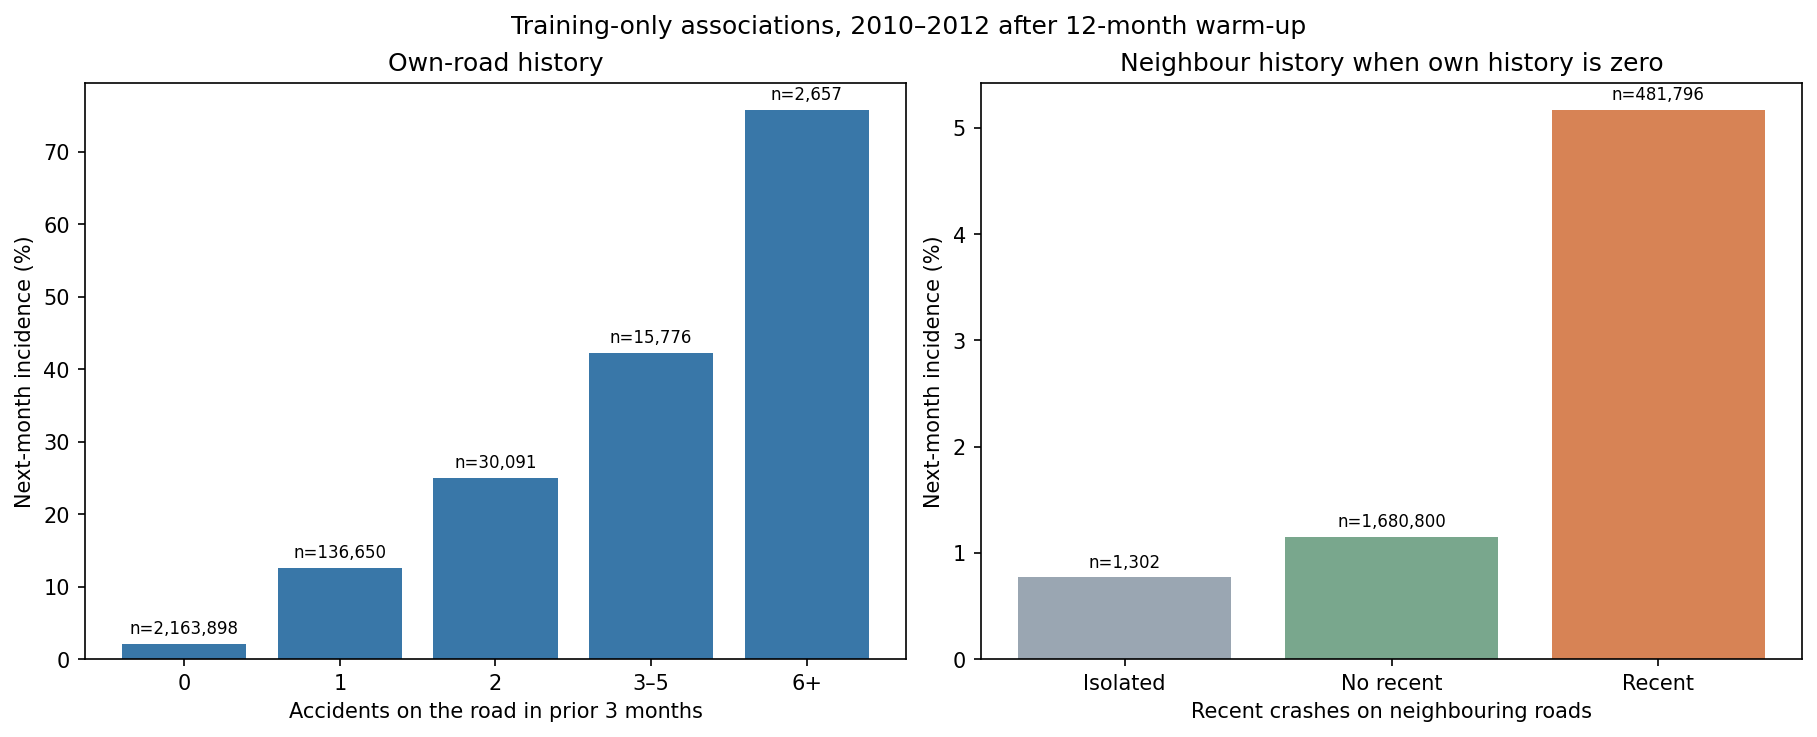

In [32]:
from src.history.report import history_association_tables, plot_history_associations

own_risk, neighbour_risk = history_association_tables(counts, neighbours)
display(own_risk.round(4))
figure = plot_history_associations(own_risk, neighbour_risk)
plt.show()

#### 3.3.5 Scaling, Missing Values and Temporal Leakage Prevention

The table below lists the ten features before encoding. For model input, we standardise them using training-period statistics and fill missing values with zero on the standardised scale. Eight binary indicators mark missing values in the six own-road and two neighbour history measures, giving **18 history columns per road**.


In [30]:
from src.history.report import history_feature_catalog

display(history_feature_catalog())

Feature,Definition,Reason for inclusion
acc_lag_1m,Own-road count at T−1,Immediate persistence
acc_mean_3m,Own-road mean over T−3…T−1,Smooth recent noise
acc_mean_6m,Own-road mean over T−6…T−1,Medium-term baseline
acc_mean_12m,Own-road mean over T−12…T−1,Annual-scale baseline
acc_lag_12m,Own-road count at T−12,Same-season reference
acc_nonzero_fraction_12m,Share of prior 12 months with count > 0,Recurring vs isolated risk
neighbor_acc_lag_1m_mean,Adjacent-road mean at T−1,Recent local context
neighbor_acc_mean_3m,Adjacent-road mean over T−3…T−1,Smoothed local context
neighbor_count,Distinct physical roads sharing an endpoint,Neighbourhood support
history_months_available_12m,Usable source months in prior year,Coverage context


The next cell applies the training-fitted scaler, maps the 18-column history vector back to both directed edges, and displays the resulting dimensions.

In [33]:
from src.data.history import HistoryScaler

scaler = HistoryScaler().fit(train_features)
road_history = scaler.transform(train_features[36], "all")
edge_history = road_history[edge_to_road]
print("January 2012 physical-road history:", road_history.shape)
print("Directed-edge history:", edge_history.shape)

January 2012 physical-road history: (65252, 18)


Directed-edge history: (116196, 18)


#### 3.3.7 Implications for Experiments

> **Not complete:** Some implications are stated above; a consolidated link between feature availability, redundancy, own-road and neighbour history, and the history experiments is not yet complete.

> Remove?


## 4. Methodology

### 4.1 Prediction Tasks and Shared Setup

We implemented Node2Vec and all four prediction models ourselves in PyTorch. MLP and edge-aware GraphSAGE are the selected reproduction baselines from Nippani et al. (2023); GatedGCN and Graph Transformer are the two additional architectures evaluated in this project, neither of which was evaluated in the original paper. Every architecture is trained separately under each of the four input configurations for both prediction tasks. The following subsections define the prediction tasks, training procedure and evaluation protocol; embedding and architecture details appear in Sections 4.2 and 4.3.



#### 4.1.1 Task Formulation and Prediction Framework

For each physical-road proxy $r$ and month $t$, let $y_{r,t}$ denote its recorded accident count. Classification predicts $\mathbb{1}(y_{r,t}>0)$, while regression predicts $y_{r,t}$, including zeros. Targets aggregate counts across directed edges with the same unordered endpoints, while message passing retains the directed graph (Section 3.1.1). Classification and regression use separately trained models.

All four models combine endpoint representations $h_u,h_v$ with the road attributes $e_{r,t}$ through a common prediction-head design:

$$s_{r,t}=f_{\theta}\!\left([h_u\,\|\,h_v\,\|\,e_{r,t}]\right).$$

Here $\|$ denotes concatenation. Graph encoders learn the endpoint representations; the MLP baseline uses the endpoint input vectors directly. Each model and task learns its own parameters. Classification applies a sigmoid to produce a score. Regression uses the scalar output, with negative values clipped to zero during evaluation.



#### 4.1.2 Training Procedure

We use the benchmark's chronological split years for Delaware (Nippani et al., 2023), restricted to the usable months identified in Section 3: January 2009 to December 2012 for training, January 2013 to December 2017 for validation, and January 2018 to September 2022 for testing. This gives 48 training, 60 validation and 57 test months on the same road network.

Each configuration uses model seeds 0, 1 and 2, Adam with a learning rate of 0.001, zero dropout and 100 training epochs (Kingma & Ba, 2014). Months are processed in shuffled order. Within each month, all accident-positive roads are retained and an equal number of zero-count roads are sampled without replacement, subject to availability. Months with fewer than ten accident-positive roads are skipped during training. Classification minimises binary cross-entropy with logits; regression minimises mean absolute error (MAE) on the raw output. Validation and testing include all physical-road proxies rather than the balanced training sample.



#### 4.1.3 Evaluation and Checkpoint Selection

Validation is performed every five epochs and at the final epoch. For each seed, the selected checkpoint has the highest full-network validation AUROC for classification or the lowest full-network validation MAE for regression. All runs complete 100 epochs, and test evaluation follows checkpoint selection.

AUROC is calculated separately for each month and averaged using the number of accident-positive roads as weights; months with only one outcome class are excluded. Average precision (AP) is calculated over pooled test road-months using scikit-learn's average-precision definition. Top-1% precision and recall are calculated from each month's highest-scoring 1% of roads, rounding the number selected upwards, and then averaged equally across months; recall excludes months without positive roads. Count MAE is averaged over all test road-months. Supplementary subgroup AUROC pools road-months within each subgroup. Results are reported as means and population standard deviations across the three selected seed checkpoints.



### 4.2 Input Features

All experiments retain the baseline inputs and fixed Node2Vec embeddings. OSM context and accident history are added to the road inputs according to the comparison in Section 4.4.



#### 4.2.1 Baseline Inputs

Baseline node inputs comprise coordinates, degree, approximate betweenness, monthly weather and weather-missingness indicators. Baseline road inputs comprise road-type indicators, length, the available traffic-volume input and its missingness indicator. Weather and traffic are standardised using training-period statistics, with missing values filled with zero after standardisation and identified by separate indicators. Fixed Node2Vec embeddings are concatenated with the node inputs as described in Section 4.2.2. These inputs form the reference setting for the feature comparisons; the data sources and preprocessing are described in Section 3.1.



#### 4.2.2 Node2Vec Structural Embeddings

Node2Vec learns node vectors from random-walk co-occurrences using a skip-gram objective (Grover & Leskovec, 2016; Mikolov et al., 2013). We implemented our own GPU-based Node2Vec-style procedure in PyTorch, including random-walk generation, skip-gram optimisation and negative sampling. This implementation replaces the benchmark's embedding backend and is one reason the study is a modified reproduction.

The saved experiment metadata records 128-dimensional embeddings, ten walks per node, a walk length of 20 nodes, a forward context window of five positions and one negative sample per positive pair. Embeddings are trained for one epoch with Adam, learning rate 0.01, starting-node batch size 1,024 and seed 0. Walks use an undirected, deduplicated version of the network. We set $p=q=1$, giving unbiased random walks rather than tuning Node2Vec's return and outward-exploration biases. The embedding run was executed on a CUDA GPU.

The resulting vectors are standardised and concatenated with the other node inputs. They are fixed during accident-model training and reused across all four architectures, input settings and model seeds. Thus, the MLP also receives network-structural information despite having no message-passing encoder. Embeddings use the known network topology without accident labels; together with evaluation on the same roads in later months, this constitutes a transductive setting. Reported seed standard deviations reflect accident-model variation with one fixed embedding and exclude variation from regenerating it. An embedding ablation is outside the report scope.



#### 4.2.3 OpenStreetMap Features

The OSM features were added to the road input of each architecture without changing the models. For each directed road $(u,v)$ in month $t$, the model receives $e_{uv,t}=[e^{\mathrm{base}}_{uv,t} \,\|\, x^{\mathrm{OSM}}_{uv}]$, where $x^{\mathrm{OSM}}_{uv}$ contains the 70 encoded OSM columns described in Section 3.2.4. The OSM columns do not vary by month, as a single map snapshot is used throughout. In the MLP, the road vector enters the shared predictor together with the representations of the road's two endpoints (Section 4.1.1). In GraphSAGE, it also contributes to the messages that each intersection receives from its neighbours; GatedGCN uses it in its edge states and gates, and the Graph Transformer in its attention scores. In the graph models, each intersection's representation therefore reflects the OSM features of the roads around it, while the predictor also receives the features of the road being scored. The figure below summarises the pipeline from the OSM snapshot to the model input. The no-OSM control uses the same setup without the 70 added columns.

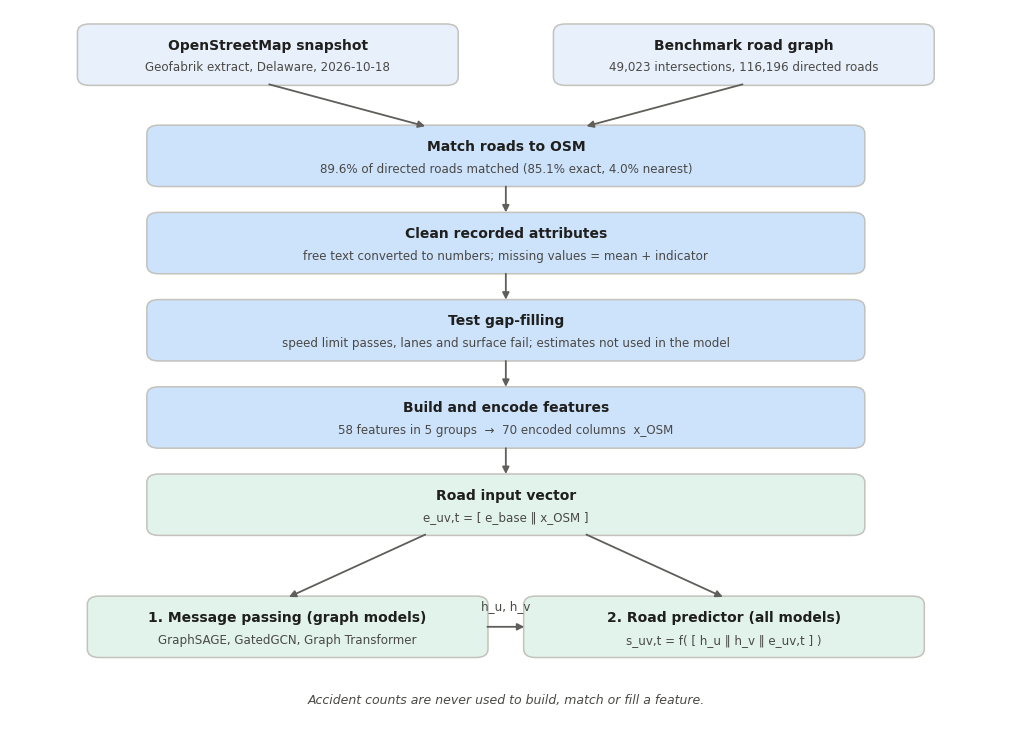

In [ ]:
from src.osm.report import load_osm_results, permutation_table, plot_osm_pipeline

fig = plot_osm_pipeline()
plt.show()

*The OSM feature pipeline for Delaware. The OSM snapshot and the benchmark road graph are matched road by road, and the recorded attributes are cleaned and encoded into the vector $x^{\mathrm{OSM}}$, which is appended to each road's input. Every model uses this input in its road predictor, and the graph models also use it in message passing. Accident counts are not used at any stage of feature construction.*

#### 4.2.4 Accident-History Features

To test the joint contribution of these features, we append the same history vector to the road inputs of each architecture. For each directed edge $(u,v)$, let $r=\{u,v\}$ denote its physical-road proxy. In target month $t$, the model receives $e_{uv,t}=[e^{\mathrm{base}}_{uv,t} \,\|\, h_{r,t}]$, where $h_{r,t}$ is the standardised physical-road history plus its missingness indicators. This is feature concatenation rather than a separate Node2Vec-style embedding. In the MLP, the road vector enters the shared predictor together with the representations of the road's two endpoints. In GraphSAGE, edge attributes also contribute to neighbourhood messages; GatedGCN projects them into its evolving edge states and gates; Graph Transformer projects them into edge-aware attention. All four models use the road-level prediction head to produce one classification score or count per physical road. The no-history control uses the same setup without the 18 added columns.



### 4.3 Model Architectures

We implemented MLP, the benchmark's edge-aware GraphSAGE adaptation, GatedGCN and Graph Transformer in PyTorch, following the established architectures (Hamilton et al., 2017; Nippani et al., 2023; Bresson & Laurent, 2017; Dwivedi & Bresson, 2020). MLP and GraphSAGE form our selected reproduction baseline pair; GatedGCN and Graph Transformer extend that pair with two established architectures not evaluated in the original paper. All four are evaluated under every input configuration in Section 4.4. Aggregation, gating and attention use native PyTorch operations rather than prebuilt graph-network layers from PyTorch Geometric or DGL.

All models use the prediction framework in Section 4.1.1. The road predictor has a 256-unit hidden layer with ReLU and a scalar output layer. Graph encoders contain two message-passing layers or Transformer blocks with hidden width 256. The architectures differ in internal operations and parameter counts, so the comparison evaluates complete models rather than isolating a single mechanism.



#### 4.3.1 MLP

The MLP baseline passes each endpoint's input vector directly to the road predictor, concatenated with the road's attributes. It therefore learns from endpoint features, fixed Node2Vec embeddings and road inputs without exchanging messages along the graph. This provides a control for assessing whether learned message passing adds value beyond the supplied structural and road-level information.



#### 4.3.2 GraphSAGE

We implement the benchmark's edge-aware GraphSAGE adaptation (Hamilton et al., 2017; Nippani et al., 2023). Each directed neighbour message combines a linear transformation of the neighbouring node's representation with a linear transformation of the connecting road's attributes. These messages and a transformed self contribution are averaged, then L2-normalised and batch-normalised. ReLU is applied between the two layers. The implementation uses all incoming neighbours, rather than sampling neighbourhoods or selecting among pooling and LSTM aggregators.

Aggregation weights are uniform, but message contents vary with node and road attributes. Consequently, GraphSAGE incorporates edge information without learning the explicit neighbour-specific gates or attention weights used by the following architectures. After two layers, the endpoint representations enter the shared predictor together with the road attributes.



#### 4.3.3 Gated Graph Convolutional Network (GatedGCN)

Our GatedGCN implementation maintains hidden states for both intersections and directed roads (Bresson & Laurent, 2017). Node and road inputs are first projected to width 256. At each layer, an edge update combines the current edge state with transformed source and destination node states. A sigmoid converts this update into a feature-wise gate. Neighbour messages are multiplied by these gates and normalised by the sum of incoming gates before being combined with a transformed self representation.

Both node and edge updates receive batch normalisation, ReLU and residual addition. The edge states evolve across the two layers, allowing subsequent gates to depend on updated road representations. Explicit self-loops are not added because self transformations and residual paths retain each node's own information. The final node states enter the shared road predictor, which also receives the original road attributes rather than the hidden edge states.



#### 4.3.4 Graph Transformer

Our Graph Transformer uses sparse, edge-aware multi-head attention over the directed road graph, following the graph-attention approach of Dwivedi and Bresson (2020) and the Transformer framework of Vaswani et al. (2017). Node inputs are projected to width 256 and processed by two blocks, each with four attention heads of width 64. For each incoming road, the attention score combines the destination query, source key and a projected road-feature vector through element-wise multiplication, followed by a scaled sum. A softmax over incoming neighbours produces the attention weights used to aggregate source value vectors.

Each block uses pre-layer normalisation, residual connections and a feedforward network with an intermediate width of 512 and GELU activation. Road attributes are projected separately in each block; hidden edge states do not evolve between blocks. Attention is restricted to existing directed edges, with no added self-loops; residual paths retain each node's own representation. The implementation retains the shared structural inputs, including Node2Vec, and does not add Laplacian positional encodings. Final node states and the original road attributes enter the shared predictor.



Graph Transformers (Dwivedi & Bresson, 2020) extend Transformers (Vaswani et al., 2017) to the graph domain by using the attention mechanism to assign weights to neighbouring nodes, restricting how nodes access and share information with one another. The attention mechanism assigns weights to these neighbours based on their representations, allowing their contributions to vary during aggregation. It also incorporates edge features into the attention mechanism, allowing attributes of the connections between nodes to influence the learned representations. In addition, Laplacian eigenvectors are used as node positional encoding to inject structural information to increase the expressivity of the models.

### 4.4 Experimental Comparisons

The main comparison crosses four architectures (MLP, GraphSAGE, GatedGCN and Graph Transformer) with four input configurations: (1) baseline, (2) baseline plus OSM context, (3) baseline plus accident history, and (4) baseline plus both OSM context and accident history. Each architecture is trained separately under every configuration for classification and regression, using seeds 0, 1 and 2. This gives 16 architecture-input combinations per task and 96 model-training runs across both tasks, excluding supplementary analyses. All settings retain the same fixed Node2Vec embeddings and use the chronological splits, training procedure and checkpoint selection in Sections 4.1.2 and 4.1.3. Feature effects are assessed within each architecture, while architecture differences are assessed with the input configuration held constant. Section 5.5 emphasises the combined-input comparison and also examines how the rankings change across configurations.

For paired feature comparisons, the same seed controls a separate sampling generator, so sampled negative roads are matched independently of model initialisation.



#### 4.4.1 Baseline: All Four Architectures



The baseline comparison evaluates all four architectures separately on classification and regression using the baseline inputs in Section 4.2, without OSM or accident-history augmentation. MLP and GraphSAGE are the selected reproduction baselines from the original paper, while GatedGCN and Graph Transformer are the additional architectures introduced into this project's comparison and were not evaluated in the original paper. Baseline-input runs for all four models establish reference scores for their corresponding feature comparisons and test whether learned message passing improves prediction beyond the supplied Node2Vec structural features.



#### 4.4.2 Adding OSM

To address RQ1, each of the four architectures is trained for both tasks with and without the 70 OSM columns, while all other inputs and training settings are kept the same, so any difference between a pair of runs can be attributed to the OSM features. The runs without OSM are the team's baseline runs.

Two further analyses are carried out for the GraphSAGE classifier. The first repeats the comparison without Node2Vec embeddings, to examine whether the OSM features and Node2Vec provide overlapping information (Section 5.3.2). The second measures how much the trained model relies on each OSM feature group, using permutation importance (Fisher et al., 2019). The values of one feature group are randomly reassigned among the test roads, so that each road receives another road's values for that group, and the resulting drop in test AUROC is recorded. A large drop indicates that the model relies heavily on that group. Each group is tested in this way, and the drops are averaged over three repetitions for each of the three trained models. Because the model is not retrained, the result reflects the model's reliance on each group rather than the value the group would add on its own.


#### 4.4.3 Adding Accident History: All Four Architectures

To address RQ2, we compare baseline inputs against baseline plus accident history for all four architectures, separately for classification and regression. This gives eight model-task comparisons. The history setting appends 18 columns describing previous accidents on the road and its neighbours, source coverage and missing values. The control uses baseline inputs without history or OSM augmentation. Within each pair, Node2Vec embeddings, model architecture and the training and evaluation protocol remain fixed.

We report each setting's mean and population standard deviation across three seeds using the metrics in Section 4.1.3, together with the history-minus-control difference calculated before rounding. Positive differences indicate improvement for AUROC, AP and top-1% precision and recall; negative differences indicate improvement for count MAE. The history runs are compared with their corresponding archived no-history controls.

#### 4.4.4 Combined Inputs: All Four Architectures

To address RQ3, we compare MLP, GraphSAGE, GatedGCN and Graph Transformer with baseline, OSM and accident-history inputs combined. All four receive the same feature groups and fixed Node2Vec embeddings and are evaluated separately on accident occurrence and counts using the shared protocol. Differences therefore describe the relative performance of the complete model architectures under a common input setting, rather than the effect of changing available information.

For each of the four architectures, the combined setting is also compared with baseline, OSM-only and history-only augmentation. These comparisons show whether combining OSM and history improves performance beyond either addition alone. They do not establish a separate causal effect for gating or attention, and architecture rankings are examined separately in each input setting.


## 5. Results and Discussion


### 5.1 Overall Performance Summary

Table 5.1 summarises Delaware test performance for all four architectures with baseline inputs, OSM added, history added and both additions combined. All settings retain fixed Node2Vec embeddings. Entries show mean and population standard deviation over three model seeds at validation-selected checkpoints. Classification metrics and count MAE come from separately trained models; higher classification scores and lower MAE are better.


In [ ]:
import json
import numpy as np
import pandas as pd

# Explicit sources avoid mixing duplicate history exports or selecting by test score.
# Baseline rows use their named no-history exports. History-only rows use
# results/history_100_epochs/v1_DE_*; alternative history exports are excluded.
# Combined rows use results/DE_*_osm_all_hist_all; OSM-only rows use results/osm/
# (MLP and GraphSAGE from the OSM notebook, GatedGCN and Graph Transformer from the
# main training script, hence the *_hist_none names). Exact paths are retained in
# architecture_summary_sources, preserving provenance across separate exports.
summary_models = [
    ("MLP", "mlp", "DE_mlp_{task}_n2v", "osm/DE_mlp_{task}_n2v_osm_all"),
    ("GraphSAGE", "graphsage", "DE_graphsage_{task}_n2v", "osm/DE_graphsage_{task}_n2v_osm_all"),
    ("GatedGCN", "gatedgcn", "DE_gatedgcn_{task}_n2v_hist_none", "osm/DE_gatedgcn_{task}_n2v_osm_all_hist_none"),
    ("Graph Transformer", "graph_transformer", "DE_graph_transformer_{task}_n2v_hist_none",
     "osm/DE_graph_transformer_{task}_n2v_osm_all_hist_none"),
]
summary_settings = ("Baseline", "Baseline + OSM", "Baseline + history", "Baseline + OSM + history")
summary_rows, summary_sources = [], []
for setting in summary_settings:
    for label, model, baseline_template, osm_template in summary_models:
        row = {"Inputs": setting, "Model": label}
        for task in ("classification", "regression"):
            if setting == "Baseline":
                relative = baseline_template.format(task=task)
            elif setting == "Baseline + OSM":
                relative = osm_template.format(task=task)
            elif setting == "Baseline + history":
                relative = f"history_100_epochs/v1_DE_{model}_{task}_n2v_hist_all"
            else:
                relative = f"DE_{model}_{task}_n2v_osm_all_hist_all"
            selected = (
                [("AUROC", "AUROC"), ("AP", "PR-AUC"),
                 ("Top-1% precision", "precision@top1%"), ("Top-1% recall", "recall@top1%")]
                if task == "classification" else [("Count MAE", "MAE")]
            )
            if relative is None:
                for column, _ in selected:
                    row[column] = "Pending incorporation"
                summary_sources.append({"Inputs": setting, "Model": label, "Task": task, "Source": "Pending incorporation"})
                continue
            path = PROJECT_DIR / "results" / relative / "metrics.json"
            payload = json.loads(path.read_text(encoding="utf-8"))
            cfg = payload["config"]
            assert payload.get("complete") and not payload.get("smoke_only"), path
            assert cfg["state"] == "DE" and cfg["model"] == model and cfg["task"] == task, path
            assert cfg["use_node2vec"] and cfg["epochs"] == 100, path
            runs = payload["runs"]
            assert sorted(run["seed"] for run in runs) == [0, 1, 2], path
            if "history" in setting:
                assert cfg.get("history_mode") == "all", path
            else:
                assert cfg.get("history_mode") in (None, "none") and not cfg.get("history_groups"), path
            if setting == "Baseline + OSM + history":
                assert cfg.get("osm_groups"), path
            for column, key in selected:
                # Match the report's population-SD convention using saved per-seed scores.
                values = np.array([run["test"]["all"][key] for run in runs], dtype=float)
                assert np.isfinite(values).all(), (path, key)
                row[column] = f"{values.mean():.4f} \u00b1 {values.std(ddof=0):.4f}"
            summary_sources.append({"Inputs": setting, "Model": label, "Task": task, "Source": str(path.relative_to(PROJECT_DIR))})
        summary_rows.append(row)

architecture_summary = pd.DataFrame(summary_rows).set_index(["Inputs", "Model"])
architecture_summary.columns = pd.MultiIndex.from_tuples([
    ("Classification", "AUROC"),
    ("Classification", "AP"),
    ("Classification", "Top-1% precision"),
    ("Classification", "Top-1% recall"),
    ("Regression", "Count MAE"),
])
architecture_summary_sources = pd.DataFrame(summary_sources)
display(architecture_summary.style.set_caption(
    "Table 5.1. Delaware test performance with fixed Node2Vec: mean and population SD over seeds 0, 1 and 2. "
    "Higher classification scores are better; lower count MAE is better."
).set_table_styles([
    {"selector": "th", "props": [("text-align", "left")]},
    {"selector": "td", "props": [("white-space", "nowrap")]},
]))


Classification                                                          Regression
                                                      AUROC               AP Top-1% precision    Top-1% recall        Count MAE
Inputs                   Model                                                                                                 
Baseline                 MLP                0.8780 ± 0.0002  0.2788 ± 0.0016  0.4822 ± 0.0022  0.1289 ± 0.0005  0.2201 ± 0.0040
                         GraphSAGE          0.8743 ± 0.0003  0.2627 ± 0.0013  0.4585 ± 0.0031  0.1226 ± 0.0009  0.2070 ± 0.0038
                         GatedGCN           0.8747 ± 0.0010  0.2714 ± 0.0031  0.4732 ± 0.0060  0.1267 ± 0.0015  0.1812 ± 0.0035
                         Graph Transformer  0.8734 ± 0.0004  0.2693 ± 0.0015  0.4671 ± 0.0028  0.1249 ± 0.0008  0.1882 ± 0.0032
Baseline + OSM           MLP                0.8807 ± 0.0001  0.2822 ± 0.0030  0.4872 ± 0.0054  0.1303 ± 0.0014  0.2122 ± 0.0057
                         GraphSAGE          0.8772 ± 0.0008  0.2740 ± 0.0017  0.4714 ± 0.0015  0.1261 ± 0.0003  0.2016 ± 0.0007
                         GatedGCN           0.8771 ± 0.0008  0.2756 ± 0.0016  0.4793 ± 0.0052  0.1282 ± 0.0014  0.1764 ± 0.0031
                         Graph Transformer  0.8756 ± 0.0009  0.2719 ± 0.0048  0.4652 ± 0.0137  0.1244 ± 0.0036  0.1767 ± 0.0039
Baseline + history       MLP                0.8858 ± 0.0005  0.3172 ± 0.0011  0.5413 ± 0.0013  0.1448 ± 0.0004  0.2199 ± 0.0052
                         GraphSAGE          0.8860 ± 0.0002  0.3250 ± 0.0009  0.5568 ± 0.0021  0.1489 ± 0.0006  0.2107 ± 0.0133
                         GatedGCN           0.8848 ± 0.0002  0.3214 ± 0.0020  0.5513 ± 0.0027  0.1474 ± 0.0007  0.1891 ± 0.0112
                         Graph Transformer  0.8837 ± 0.0003  0.3183 ± 0.0019  0.5441 ± 0.0024  0.1455 ± 0.0006  0.1530 ± 0.0020
Baseline + OSM + history MLP                0.8878 ± 0.0000  0.3199 ± 0.0016  0.5421 ± 0.0028  0.1450 ± 0.0008  0.2235 ± 0.0081
                         GraphSAGE          0.8877 ± 0.0005  0.3261 ± 0.0008  0.5579 ± 0.0004  0.1492 ± 0.0001  0.1999 ± 0.0063
                         GatedGCN           0.8868 ± 0.0004  0.3243 ± 0.0003  0.5538 ± 0.0023  0.1481 ± 0.0006  0.1764 ± 0.0044
                         Graph Transformer  0.8856 ± 0.0006  0.3203 ± 0.0014  0.5472 ± 0.0018  0.1463 ± 0.0005  0.1564 ± 0.0016

### 5.2 Baseline Performance: All Four Architectures


MLP and GraphSAGE are the two baselines selected from the original paper for modified reproduction; GatedGCN and Graph Transformer extend our comparison with two architectures not evaluated in the original paper. All four have baseline-input results in Table 5.1.

With baseline inputs and fixed Node2Vec embeddings, MLP achieves higher mean classification AUROC than GraphSAGE (0.8780 versus 0.8743). The same ordering holds for AP (0.2788 versus 0.2627) and top-1% precision (48.22% versus 45.85%). Thus, MLP's stronger occurrence ranking also translates into a more productive shortlist of high-risk roads.

For count regression, GraphSAGE has lower mean MAE (0.2070 versus 0.2201). GatedGCN and Graph Transformer achieve baseline AUROCs of 0.8747 and 0.8734, respectively, also below MLP, but have lower count MAEs of 0.1812 and 0.1882. MLP therefore leads all four baseline-input classifiers on AUROC, AP and top-1% precision and recall, while GatedGCN has the lowest count MAE. Learned message passing has a task-dependent benefit in this baseline setting. Because both models already receive Node2Vec, this comparison assesses the additional value of the GraphSAGE encoder beyond the supplied structural features.



### 5.3 RQ1: Effect of OSM Features

Adding the OSM features improves all four architectures (Table 5.1). Test AUROC rises by 0.002 to 0.003 for every architecture, with all three seeds improving, and count MAE falls by 3 to 6%. The other classification metrics mostly improve as well, although less consistently across seeds for GatedGCN and the Graph Transformer. The MLP, which does not pass messages between roads, gains as much as the graph models, which suggests that the features help mainly as information about the road being scored rather than through message passing. The remainder of this section examines the GraphSAGE classifier in more detail: which feature groups it relies on, whether the gain holds over time and across road types, and why the gain is small once Node2Vec embeddings are included.


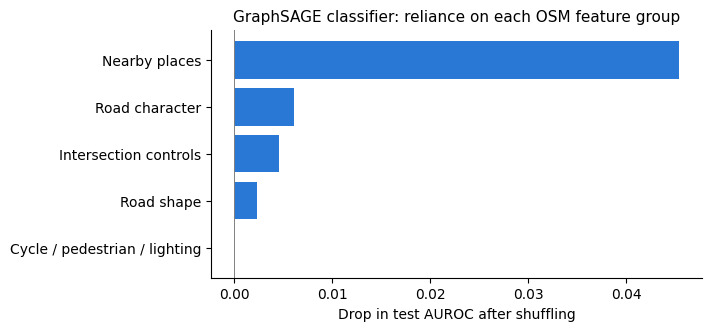

In [ ]:
osm_results = load_osm_results(PROJECT_DIR)
groups = ['Nearby places', 'Road character', 'Intersection controls', 'Road shape',
          'Cycle / pedestrian / lighting']
drops = permutation_table(osm_results).loc[groups, 'With Node2Vec']

fig, ax = plt.subplots(figsize=(7, 3.2), constrained_layout=True)
ax.barh(groups, drops)
ax.invert_yaxis()
ax.axvline(0, color='grey', linewidth=0.7)
ax.set(xlabel='Drop in test AUROC after shuffling', title='GraphSAGE classifier: reliance on each OSM feature group')
plt.show()

*Drop in test AUROC when each OSM feature group is shuffled across test roads, for the GraphSAGE classifier with Node2Vec; mean over three repetitions for each of three seeds.*

#### 5.3.1 Feature Groups and Consistency of the Gain

The figure above shows how much the trained GraphSAGE classifier relies on each OSM feature group. Shuffling the nearby-place features reduces test AUROC by 0.045, more than half of the drop caused by shuffling all OSM features together (0.079). Every other group causes a drop of less than 0.007, and the cycle, pedestrian and lighting group has no measurable effect. This ranking follows coverage: nearby places are available for every road, whereas attributes such as speed limits, lanes and lighting are recorded for only a minority of roads. Nearby-place counts may also partly stand in for traffic volume, which is recorded for only 3% of roads.

The gain is also consistent over time and across road types. Monthly AUROC is higher with the OSM features in all 57 test months, with a mean increase of 0.0029. The gain is larger on motorways (0.014 across 706 roads) than on residential roads (0.003 across 44,294 roads), which is consistent with the more complete mapping of major roads, although the two road types also differ in accident frequency. These two analyses use the saved predictions of each model and are reported in `notebooks/osm_baseline_comparison.ipynb` (Sections 10 and 11).


#### 5.3.2 Why the Gain Is Small with Node2Vec

All comparisons above include Node2Vec embeddings. To test whether the OSM features and Node2Vec carry overlapping information, the GraphSAGE classifier was also trained with and without the OSM features after removing Node2Vec. The table below shows the four combinations.

| Test AUROC (mean ± SD, 3 seeds) | No OSM | With OSM | Change |
|---|---|---|---|
| Without Node2Vec | 0.8461 ± 0.0037 | 0.8713 ± 0.0008 | +0.0252 |
| With Node2Vec | 0.8743 ± 0.0003 | 0.8772 ± 0.0008 | +0.0029 |

*GraphSAGE classification in Delaware with and without OSM features and Node2Vec embeddings. The control without Node2Vec is the team's committed baseline run. Source: `notebooks/osm_baseline_comparison.ipynb`, Section 8.1.*

Without Node2Vec, the OSM features improve AUROC almost nine times as much as with it, and precision among the 1% of roads ranked as most at risk rises from 0.392 to 0.445. The two inputs therefore largely overlap: each improves AUROC by a similar amount on its own, but adding both gives only slightly more than adding either one. The model also relies less on the nearby-place features when Node2Vec is present.

To understand this overlap, we examined whether Node2Vec already encodes how built-up a road's surroundings are. For each road, we counted the places recorded in OSM within 1 km and fitted a model to predict this count from the road's Node2Vec embedding (`notebooks/osm_node2vec_density_check.ipynb`). The model was tested in two ways. When the test roads lay in parts of the state not used for fitting, it could not predict the count (R² of 0.06). When the test roads were chosen at random, so that neighbouring roads had been used for fitting, it predicted the count well (R² of 0.68). This shows that Node2Vec does not encode how built-up an area is; instead, nearby roads receive similar embeddings, so Node2Vec indicates where a road is located. Because the same roads are used for training and testing, knowing where a road is located already tells the model much about its accident risk, which leaves little for the OSM features to add.


### 5.4 RQ2: Effect of Accident History

Adding the 18 history inputs improved classification ranking for all four architectures. For count regression, the models also became better at identifying crash-positive roads near the top of the ranking, but their count errors changed in different directions. The tables below compare each model with its no-history Node2Vec baseline on the same Delaware test months. Entries show mean ± population standard deviation over three seeds, followed by the full-history minus baseline difference calculated before rounding.

In [ ]:
from src.history.report import load_history_results, history_comparison_table

full_history_root = PROJECT_DIR / "results" / "history_100_epochs"
history_results = load_history_results(PROJECT_DIR / "results", full_history_root)
for task in ("classification", "regression"):
    print("Classification" if task == "classification" else "Count regression")
    table = history_comparison_table(history_results, task)
    display(table.loc[table["Model"].isin(["MLP", "GraphSAGE"])])

Table 12. Classification


,Model,AUROC,AP,Precision@top1%
0,MLP,0.8780 ± 0.0002 → 0.8858 ± 0.0005 (+0.0077),0.2788 ± 0.0016 → 0.3172 ± 0.0011 (+0.0384),0.4822 ± 0.0022 → 0.5413 ± 0.0013 (+0.0591)
1,GraphSAGE,0.8743 ± 0.0003 → 0.8860 ± 0.0002 (+0.0117),0.2627 ± 0.0013 → 0.3250 ± 0.0009 (+0.0623),0.4585 ± 0.0031 → 0.5568 ± 0.0021 (+0.0983)


Table 13. Count regression


,Model,AUROC,AP,MAE,Precision@top1%
0,MLP,0.8648 ± 0.0011 → 0.8732 ± 0.0008 (+0.0084),0.2372 ± 0.0029 → 0.2674 ± 0.0071 (+0.0302),0.2201 ± 0.0040 → 0.2199 ± 0.0052 (-0.0001),0.3651 ± 0.0097 → 0.4369 ± 0.0144 (+0.0718)
1,GraphSAGE,0.8569 ± 0.0025 → 0.8580 ± 0.0045 (+0.0011),0.2196 ± 0.0034 → 0.2550 ± 0.0086 (+0.0354),0.2070 ± 0.0038 → 0.2107 ± 0.0133 (+0.0037),0.3179 ± 0.0116 → 0.4002 ± 0.0353 (+0.0823)


#### 5.4.1 Model gains across the two tasks

MLP had the highest baseline AUROC (0.8780), ahead of GraphSAGE (0.8743), GatedGCN (0.8747) and Graph Transformer (0.8734). With history, GraphSAGE reached 0.8860 and MLP reached 0.8858. GatedGCN and Graph Transformer gained similar amounts (+0.0100 and +0.0104), finishing at 0.8848 and 0.8837. The differences were more pronounced in average precision. GraphSAGE rose from 0.2627 to 0.3250, the largest gain (+0.0623), while MLP started from the strongest baseline and gained the least (+0.0384). All four classifiers improved in AUROC, AP and top-1% precision in each of the three same-seed comparisons.

The ordering changed when the target was the number of crashes. GatedGCN had the lowest baseline MAE (0.1812), but Graph Transformer had the lowest full-history MAE, dropping from 0.1882 to 0.1530. Its error fell in all three seeds. MLP changed little on average (0.2201 to 0.2199), while GraphSAGE and GatedGCN had slightly higher errors with history (0.2070 to 0.2107 and 0.1812 to 0.1891). For each of these three architectures, the direction of the MAE change varied across seeds. At the same time, the mean AP and top-1% precision of the count predictions rose for all four models. History thus improved their ability to identify roads likely to see a crash more consistently than it improved their estimates of how many crashes would occur.

**GraphSAGE gained the most in classification, while its final AUROC was only 0.0002 above MLP’s.** Recent crash counts and recurrence already summarise risk at the road level, which gives even an MLP useful information without learned message passing. The similar AUROC gains for GatedGCN and Graph Transformer also suggest that the ranking benefit extends across different graph encoders. 

**Graph Transformer’s overall MAE improvement came from quieter roads.** Its MAE fell from 0.1773 to 0.1361 on zero-crash road-months but rose from 0.4698 to 0.5861 on crash-positive ones. Zero counts dominate the network, so more accurate predictions on quiet roads outweighed larger errors where crashes occurred. GraphSAGE illustrates the opposite trade-off: its error on crash-positive roads fell from 0.4517 to 0.4317, yet the smaller increase on the much larger zero-crash group raised overall MAE.

#### 5.4.2 Implications for road screening

For a road agency with a fixed monthly inspection budget, the top of the ranking has a direct interpretation. Among the 1% of roads prioritised by GraphSAGE, precision increased from 45.85% to 55.68%. **For every 100 roads on the list, about ten more subsequently recorded a crash.** Recall increased from 12.26% to 14.89%, so the list became more productive while still covering only a fraction of the roads with recorded crashes. Figure H2 offers one reason historical context could help with this decision: even after a crash-free quarter on the road itself, next-month incidence was 1.15% when its neighbours also had no recent crashes and 5.17% when at least one did. This association helps explain why two apparently quiet roads might warrant different priorities. The model comparisons quantify the benefit of the complete history vector.

#### 5.4.3 Training dynamics and computational cost

The distinction between screening and counting also matters during training. Both tasks sample crash-positive and zero-crash roads in equal numbers during training and evaluate on all roads in each held-out month. For classification, one crash and several crashes give the same positive label. The model minimises binary cross-entropy, and we select the checkpoint with the highest validation AUROC. For regression, each additional crash changes the target. The model minimises absolute count error, and we select the checkpoint with the lowest validation MAE. Each seed’s selected checkpoint is then scored on the test months. Given these different objectives, how much of the common 100-epoch budget did each task actually use? Figures H3 and H4 compare the mean trajectories over three seeds. The tables give the checkpoint selected separately for each seed.

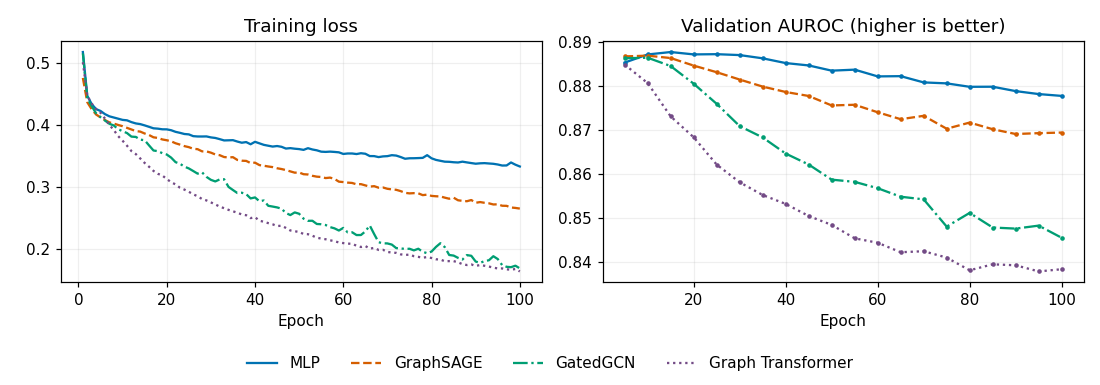

In [ ]:
from src.history.report import plot_history_training_summary

figure = plot_history_training_summary(full_history_root, "classification")
display(figure)
plt.close(figure)

*Full-history classification. Lines show the mean across three seeds for each architecture.*

Across four classifiers and three seeds, **nine of the twelve highest observed validation AUROCs occurred by epoch 10**. Graph Transformer peaked at the first evaluation, epoch 5, for every seed. GatedGCN and GraphSAGE peaked at epochs 5 or 10, while MLP continued to improve slightly longer and selected epochs 15, 15 and 30. By epoch 100 every classifier had a lower training loss and a lower validation AUROC than at its selected checkpoint. The mean AUROC decline was largest for Graph Transformer (0.0464) and smallest for MLP (0.0100). This divergence is consistent with late-stage overfitting. For future classification runs, validation-based early stopping could save computation, with enough patience to accommodate the later MLP peaks.

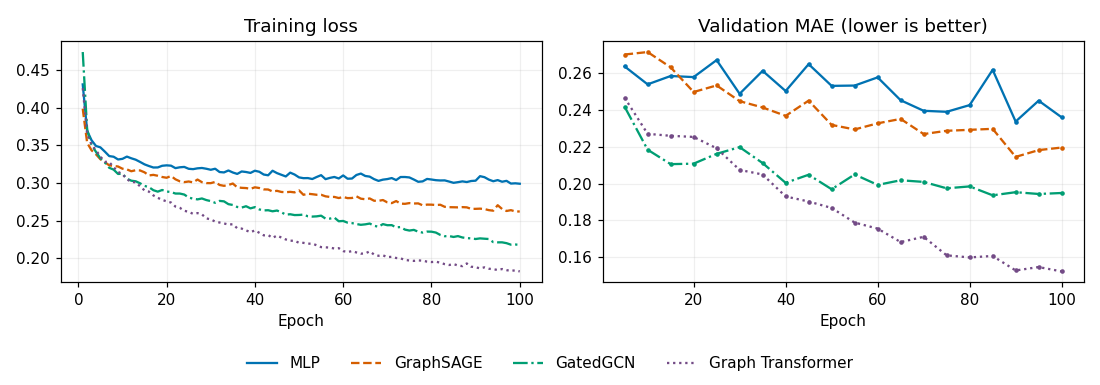

In [ ]:
figure = plot_history_training_summary(full_history_root, "regression")
display(figure)
plt.close(figure)

*Full-history regression. Lines show the mean across three seeds for each architecture.*

Count regression continued to benefit from training well beyond the classification peaks. **All twelve regression runs reached their lowest observed validation MAE between epochs 65 and 100.** GraphSAGE selected epochs 90, 100 and 95, and Graph Transformer selected 90, 100 and 100. In the runs selected at epoch 100, the best observed value lies at the boundary of the training record. Extending the budget from 90 to 100 epochs reduced the best validation MAE by a further 0.0052 for MLP, 0.0047 for GraphSAGE, 0.0019 for GatedGCN and 0.0025 for Graph Transformer, averaged over seeds.

The cost of those late improvements depended more on architecture than on task in the recorded runs. The table gives mean wall-clock seconds per epoch for one seed, averaging all 100 epochs across the three seeds, including scheduled validation.

| Model | Classification (s/epoch) | Regression (s/epoch) |
|---|---:|---:|
| MLP | 4.92 | 4.73 |
| GraphSAGE | 6.92 | 6.68 |
| GatedGCN | 10.60 | 10.43 |
| Graph Transformer | 9.84 | 9.85 |

The final ten regression epochs cost about 2.3 minutes for MLP across three seeds and 5.1 minutes for GatedGCN. MLP therefore obtained the largest late reduction in validation MAE at the lowest time cost, whereas GatedGCN spent the most time for the smallest late reduction. For exploratory runs, the observed trade-off favours allowing a longer budget for regression and monitoring validation AUROC early for classification. The reported test comparisons use the same 100-epoch budget throughout.

### 5.5 RQ3: Effect of Model Architecture Across Input Configurations

Sections 5.2-5.4 establish baseline performance and the effects of OSM and history separately. This section focuses on differences between architectures, using the combined-input results and changes in architecture rankings across the four configurations in Table 5.1. Classification and regression use separately trained models.

#### 5.5.1 Combined-Input Classification: Overall Ranking and Hotspot Screening

With all inputs combined, MLP has the highest mean AUROC (0.8878), followed by GraphSAGE (0.8877), GatedGCN (0.8868) and Graph Transformer (0.8856). The unrounded MLP-GraphSAGE gap is approximately 0.00013, smaller than GraphSAGE's seed standard deviation (0.00047). MLP does not outperform GraphSAGE on AUROC in every same-seed comparison, so the means do not establish a reliable separation between the leading pair.

GraphSAGE leads the metrics most directly related to screening: AP is 0.3261, compared with 0.3243 for GatedGCN, 0.3203 for Graph Transformer and 0.3199 for MLP. Its top-1% precision and recall are also highest, at 55.79% and 14.92%, respectively. Relative to MLP, its shortlist contains about 1.6 more accident-positive roads per 100 selected roads. GraphSAGE has higher AP and top-1% precision than each alternative in all three same-seed comparisons, although this does not establish statistical significance or robustness beyond the evaluated setting.

#### 5.5.2 Combined-Input Regression: Overall Error and Accident-Positive Roads

Graph Transformer has the lowest overall MAE (0.1564), followed by GatedGCN (0.1764), GraphSAGE (0.1999) and MLP (0.2235). This ordering holds in each same-seed comparison. The Transformer's advantage over GatedGCN is approximately 0.0199 accidents per road-month in the mean.

The ordering reverses on accident-positive road-months: MAE is lowest for MLP (0.4339), followed by GraphSAGE (0.4439), GatedGCN (0.5060) and Graph Transformer (0.5661). On zero-accident road-months, the respective errors are 0.2153, 0.1904, 0.1635 and 0.1405. This extends the history-only subgroup analysis in Section 5.4.1 to an architecture comparison with combined inputs: the Transformer leads overall by reducing errors on the much larger zero-count group, while MLP is more accurate where accidents occur.

#### 5.5.3 What Changes When the Inputs Are Combined?

The separate-addition results in Sections 5.3 and 5.4 do not establish whether using both feature groups is preferable. Adding OSM to history increases mean AUROC by 0.0020 for MLP, 0.0016 for GraphSAGE, 0.0020 for GatedGCN and 0.0019 for Graph Transformer. AP and top-1% precision and recall also increase in the mean for every architecture. Thus, combined inputs produce each classifier's highest mean scores, although the small increments over history alone warrant caution with three seeds.

For regression, adding OSM to history reduces mean MAE for GraphSAGE (0.2107 to 0.1999) and GatedGCN (0.1891 to 0.1764), but increases it for MLP (0.2199 to 0.2235) and Graph Transformer (0.1530 to 0.1564). The best count configuration in Table 5.1 is therefore Graph Transformer with history alone, rather than all inputs combined. These comparisons establish that combining features can change performance differently across architectures; they do not identify a feature-interaction mechanism.

#### 5.5.4 Interpreting Architecture Differences

**MLP and GraphSAGE: direct features versus additional propagation.** The Node2Vec and engineered-history explanations in Sections 5.3.2 and 5.4.1 help account for MLP's competitive ranking. The architectural distinction is how the models use information beyond the target road: GraphSAGE incorporates connecting-road attributes into neighbourhood messages, whereas MLP uses the supplied endpoint and road vectors directly (Sections 4.3.1-4.3.2). With history present, GraphSAGE can propagate historical road information through its two graph layers in addition to receiving the predefined neighbour-history summaries. Its stronger AP and screening results are consistent with a benefit from this additional aggregation. Testing that explanation would require retaining history in the prediction head while removing it from graph messages and retraining.

**GatedGCN: learned gates versus uniform averaging.** GatedGCN can vary neighbouring roads' contributions through feature-wise gates and evolving edge states (Section 4.3.3). Its lead in baseline and OSM-only count MAE does not extend to the history configurations, and its adaptive weighting does not surpass GraphSAGE's history-based screening. The extra flexibility therefore changes performance without providing a consistent advantage. The scores do not show which roads its gates emphasise or establish that gating causes the observed differences.

**Graph Transformer: selective spatial aggregation, not temporal attention.** Its attention scores depend on endpoint representations and connecting-road attributes (Section 4.3.4). History can therefore affect the weighting of neighbouring intersections, offering a possible explanation for its stronger regression performance in the history configurations. However, this is local attention over the road graph: the model receives historical summaries and does not attend over a sequence of past months. The subgroup reversal in Section 5.5.2 also limits the interpretation of its overall MAE: flexible attention is not evidence of uniformly better count estimates. Isolating its contribution would require an otherwise matched uniform-attention control; inspecting attention weights alone would not establish their causal effect.

#### 5.5.5 Contribution of the Added Architectures and Answer to RQ3

GatedGCN and Graph Transformer, neither evaluated in the original paper, broaden the comparison beyond the selected MLP and GraphSAGE reproduction baselines. Both achieve lower mean overall count MAE than those baselines in every input configuration, but neither consistently improves classification. Their addition reveals a task-dependent benefit: adaptive graph encoders are competitive for overall count error, while the simpler GraphSAGE provides the strongest combined-input screening and MLP remains competitive on AUROC.

These are comparisons of complete implementations under the shared Delaware protocol and one fixed Node2Vec embedding. Gating and attention are not isolated from parameter counts, normalisation or other transformations, and three seeds do not establish statistical significance. The answer to RQ3 is therefore conditional on the inputs and evaluation objective: the added models improve overall count MAE, but greater architectural flexibility does not consistently improve accident-occurrence ranking or performance on accident-positive roads.



## 6. Limitations and Future Work



### 6.1 Temporal Validity and Data Availability

The OSM snapshot dates from 2026, whereas the accident records cover 2009 to 2022, so the features describe roads as they are today rather than as they were when each accident occurred. A safety measure introduced after a series of accidents, such as a new traffic signal, may therefore be visible to the model for years in which it did not yet exist, which could overstate predictive performance. A single snapshot was used because processing one extract per accident year was beyond the resources of this project. Geofabrik provides dated extracts from 2014 onwards, so matching each accident year to the closest available snapshot is a feasible next step.

Accident-history features use only records preceding the target month, but assume those records are complete and available at prediction time. Reporting delays would particularly affect the one-month lag and recent rolling windows. Future evaluations should withhold the most recent month or months of accident records, or reconstruct the inputs from dated releases where available, to measure sensitivity to delayed reporting.

Traffic volume is recorded for only 3.16% of physical roads, and several OSM attributes, such as speed limits, lanes and lighting, are recorded for only a minority of roads, mostly major ones. Missing-value indicators show the model where information is absent but cannot replace it. More complete sources, such as state road inventories and traffic counts, would help separate the effect of road characteristics from that of traffic volume.


### 6.2 Generalisation and Experimental Scope

The evaluation concerns Delaware roads observed in later months on the same network. It does not establish performance on unseen roads, in other states or on a different road network. Additional states and spatially held-out evaluations are needed to assess geographic generalisation. Evaluations on new networks would also need to specify how Node2Vec embeddings are generated and aligned with the prediction model.

Each configuration uses three model seeds and one fixed Node2Vec embedding. The reported standard deviations capture variation between these model runs, but exclude uncertainty from embedding generation, geographic sampling and alternative chronological splits. Repeating the comparisons with independently trained embeddings, more model seeds and additional time windows would test whether small architecture differences persist.

The architecture comparison also holds the training budget and hidden width fixed rather than equalising parameter counts or conducting a separate extensive hyperparameter search for every model. Its results describe the implemented configurations under the shared protocol, rather than the best attainable performance of each architecture. Broader tuning under a declared compute budget would strengthen comparisons of model families.



### 6.3 Feature Design and Interpretation

Rolling accident summaries overlap and compress the ordering of past events. Roads with increasing and decreasing accident frequency can have the same rolling mean, while longer-window counts and recurrence measures can carry similar information. Future comparisons could replace redundant summaries with time since the last accident, recency-weighted counts or representations that preserve the temporal sequence.

Neighbour history currently gives equal weight to roads sharing a junction, even when their geometry and traffic relationships differ. Geometry-aware weights or separate summaries for roads continuing along a corridor and crossing roads could test whether more selective neighbourhoods improve prediction, drawing on the use of road geometry in TRAVEL (Huang and Hooi, 2022).

Permutation importance measures reliance by a fitted model. Correlated inputs can substitute for one another, and shuffling can disrupt their joint distribution, so the resulting AUROC drops are not additive or causal feature contributions. Retraining with individual feature groups removed would provide a complementary assessment of their predictive value.

Static OSM features are standardised over the full network, whereas temporal weather and traffic statistics and the accident-history scaler are fitted using training-period data. Full-network static preprocessing is consistent with access to a known network, but does not test an inductive setting in which new roads arrive later. Future spatial holdouts should fit preprocessing on the training partition and apply it unchanged to held-out roads.



### 6.4 Evaluation and Operational Use

Balanced training changes the positive-class prevalence, and classification calibration has not been evaluated. Sigmoid scores should therefore be treated as ranking scores rather than validated accident probabilities. Calibration should be assessed and, where necessary, fitted on a separate validation period before probability-based operational use.

Temporal dependence also limits uncertainty estimates based on independent months. Resampling contiguous blocks of months or evaluating across multiple chronological windows would better preserve temporal structure when assessing differences between feature settings and architectures.

Zero-accident road-months dominate overall count MAE. As the combined-input results show, lower overall error can coexist with higher error on accident-positive roads. Reporting errors separately for zero and positive targets, alongside AP and top-1% screening metrics, is necessary to assess the trade-off. Evaluation stratified by recent accident history would also show whether gains extend to roads without recent crashes or mainly concern roads with recurring accidents.

Finally, retrospective predictive gains do not establish that an intervention guided by the predictions would prevent accidents. The interactive map supports exploration of recorded and predicted risk, but operational value would require prospective evaluation with realistic reporting delays, resource constraints and intervention outcomes.



## 7. Conclusion

This study examines monthly accident-occurrence and count prediction on physical-road proxies in Delaware through a modified reproduction of ML4RoadSafety. We selected MLP and GraphSAGE from the original paper as our reproduction baselines and extended the comparison with GatedGCN and Graph Transformer, neither of which was evaluated in that paper. These additions apply established architectures to the benchmark setting rather than introduce new architectures. We implemented GPU-based Node2Vec-style embedding generation and all four prediction models in PyTorch, developed OSM and accident-history feature pipelines, and provided an interactive map for exploring recorded and predicted road risk. Every architecture was trained separately under baseline, baseline plus OSM, baseline plus history and baseline plus both additions, for classification and regression. The experiments assess road context, prior accidents and architecture using a shared chronological evaluation with fixed Node2Vec embeddings.

For RQ1, adding OSM context improves all four architectures on both tasks: test AUROC rises by 0.002 to 0.003 and count MAE falls by 3 to 6%, with nearby-place features showing the greatest measured permutation sensitivity. The gain is small because the OSM features overlap with Node2Vec, which allows the model to recognise roads in known locations; without Node2Vec, the OSM features raise GraphSAGE's AUROC by 0.025. For RQ2, history improves occurrence ranking for all four architectures, while count-MAE effects are mixed. Historical information therefore provides a more consistent benefit for prioritising accident-prone roads than for reducing count error.

For RQ3, architecture rankings vary across input configurations and no architecture leads across all criteria. With combined inputs, MLP and GraphSAGE achieve similar mean AUROC, while GraphSAGE leads AP and top-1% precision and recall. Graph Transformer has the lowest overall count MAE, but its lower error on zero-accident road-months accompanies higher error on accident-positive ones. These findings show why architecture comparisons should retain strong controls without message passing and report metrics that reflect the intended prediction use.

The evidence supports predictive improvements conditional on the available inputs and Delaware evaluation. Retrospective map timing, incomplete exposure data and evaluation on a known network limit prospective and geographic interpretation. Historical-map evaluations, reporting-delay sensitivity checks and additional geographic and temporal holdouts are the main next steps towards establishing whether these gains persist in practical forecasting.



## 8. References

Ahmad, N., Wali, B., Khattak, A. J., & Dumbaugh, E. (2021). Built environment, driving errors and violations, and crashes in naturalistic driving environment. Accident Analysis & Prevention, 157, 106158.

Boeing, G. (2025). Modeling and analyzing urban networks and amenities with OSMnx. Geographical Analysis.

Bresson, X., & Laurent, T. (2017). Residual gated graph convnets. arXiv Preprint arXiv:1711.07553.

Briz-Redon, A., Iftimi, A., & Montes, F. (2022). Accounting for previous events to model and predict traffic accidents at the road segment level: A study in Valencia (Spain). Physica A: Statistical Mechanics and Its Applications, 585, 126416.

Castillo, R. C., Staguhn, E. D., & Weston-Farber, E. (2020). The effect of state-level stay-at-home orders on COVID-19 infection rates. American Journal of Infection Control, 48(8), 958–960.

Defferrard, M., Bresson, X., & Vandergheynst, P. (2016). Convolutional neural networks on graphs with fast localized spectral filtering. Advances in Neural Information Processing Systems, 29.

Dwivedi, V. P., & Bresson, X. (2020). A generalization of transformer networks to graphs. arXiv Preprint arXiv:2012.09699.

Fisher, A., Rudin, C., & Dominici, F. (2019). All models are wrong, but many are useful: Learning a variable's importance by studying an entire class of prediction models simultaneously. Journal of Machine Learning Research, 20(177), 1–81.

Gao, X., Jiang, X., Haworth, J., Zhuang, D., Wang, S., Chen, H., & Law, S. (2024). Uncertainty-aware probabilistic graph neural networks for road-level traffic crash prediction. Accident Analysis & Prevention, 208, 107801.

Geofabrik GmbH, & OpenStreetMap contributors. (2026). Delaware OpenStreetMap extract, 18 October 2026 (delaware-261018.osm.pbf) [Data set]. Open Database Licence 1.0. https://download.geofabrik.de/north-america/us/delaware.html

Goodchild, M. F., & Hunter, G. J. (1997). A simple positional accuracy measure for linear features. International Journal of Geographical Information Science, 11(3), 299–306. https://doi.org/10.1080/136588197242419

Grover, A., & Leskovec, J. (2016). node2vec: Scalable feature learning for networks. Proceedings of the 22nd ACM SIGKDD International Conference on Knowledge Discovery and Data Mining, 855–864.

Guerra, A., Gadhiya, V., & Srisurin, P. (2022). Crash prediction on road segments using machine learning methods. ASEAN Engineering Journal, 12(3), 27–37.

Haklay, M. (2010). How good is volunteered geographical information? A comparative study of OpenStreetMap and Ordnance Survey datasets. Environment and Planning B: Planning and Design, 37(4), 682–703. https://doi.org/10.1068/b35097

Hamilton, W., Ying, Z., & Leskovec, J. (2017). Inductive representation learning on large graphs. Advances in Neural Information Processing Systems, 30.

Hochreiter, S., & Schmidhuber, J. (1997). Long short-term memory. Neural Computation, 9(8), 1735–1780.

Huang, B., & Hooi, B. (2022). Traffic accident prediction using graph neural networks: New datasets and the TRAVEL model. Traffic, 27(29), 31.

Kashifi, M. T., Al-Turki, M., & Sharify, A. W. (2023). Deep hybrid learning framework for spatiotemporal crash prediction using big traffic data. International Journal of Transportation Science and Technology, 12(3), 793–808.

Kingma, D. P., & Ba, J. (2014). Adam: A method for stochastic optimization. arXiv Preprint arXiv:1412.6980.

Kipf, T. N., & Welling, M. (2016). Semi-supervised classification with graph convolutional networks. arXiv Preprint arXiv:1609.02907.

Ma, Z., Zhang, H., Steven, I., Chien, J., Wang, J., & Dong, C. (2017). Predicting expressway crash frequency using a random effect negative binomial model: A case study in China. Accident Analysis & Prevention, 98, 214–222.

MacKinnon, J. G., & White, H. (1985). Some heteroskedasticity-consistent covariance matrix estimators with improved finite sample properties. Journal of Econometrics, 29(3), 305–325.

Mikolov, T., Chen, K., Corrado, G., & Dean, J. (2013). Efficient estimation of word representations in vector space. arXiv Preprint arXiv:1301.3781.

Nippani, A., Li, D., Ju, H., Koutsopoulos, H., & Zhang, H. (2023). Graph Neural Networks for Road Safety Modeling: Datasets and Evaluations for Accident Analysis. Advances in Neural Information Processing Systems Datasets and Benchmarks Track, 36.

OpenStreetMap contributors. (n.d.). Key:maxspeed. OpenStreetMap Wiki. https://wiki.openstreetmap.org/wiki/Key:maxspeed

Perozzi, B., Al-Rfou, R., & Skiena, S. (2014). Deepwalk: Online learning of social representations. Proceedings of the 20th ACM SIGKDD International Conference on Knowledge Discovery and Data Mining, 701–710.

Vaswani, A., Shazeer, N., Parmar, N., Uszkoreit, J., Jones, L., Gomez, A. N., Kaiser, Ł., & Polosukhin, I. (2017). Attention is all you need. Advances in Neural Information Processing Systems, 30.

Wijnen, W., & Stipdonk, H. (2016). Social costs of road crashes: An international analysis. Accident Analysis & Prevention, 94, 97–106.

## 9. Team Contributions

*To be confirmed by each member.*

| Member | Role | Sections | Code and notebooks |
|---|---|---|---|
| Aaron Teo Rui Kang | Original Data and Map | Data and Exploration (benchmark, EDA, interactive map) | `src/eda.py`, `src/visualization/risk_map.py` |
| Cheong Fung Wei | Baseline Models and Evaluation | Methodology (prediction tasks, baseline models); Experimental Setup; Results (baselines) | `src/model/`, `src/eval/`, `notebooks/train_baseline.ipynb` |
| Duggal Vidurveer | OpenStreetMap Features | 3.2 OpenStreetMap Road Context; 4.2.3 OpenStreetMap Features; 4.4.2 Adding OSM; 5.3 RQ1: Effect of OSM Features; 6.1 (OSM limitations); Appendix A | `src/osm/`, `notebooks/osm_features_and_eda.ipynb`, `notebooks/osm_baseline_comparison.ipynb`, `notebooks/osm_node2vec_density_check.ipynb` |
| Liu Jing Jing | Accident History Features | Accident-history construction and EDA; history features (Methodology); accident-history experiments (Experimental Setup, Results and Discussion); accident-history limitations | `src/history/`, `src/data/history.py`, `notebooks/accident_history_eda.ipynb`, `notebooks/train_accident_history.ipynb`, `results/history_100_epochs/` |
| Jason Ciu Putra Sung | Additional Models and Evaluation | GatedGCN & Graph Transformers Implementation, RQ3 | `src/model/gatedgcn/`, `src/model/graph_transformer/`, `notebooks/train_baseline+gated_gcn+graph_transformer.ipynb` |

## Appendix A. OpenStreetMap Features

### A.1 Feature Catalogue

| Group | Feature | Definition | OSM source | Type | Encoding | Roads with a value |
|---|---|---|---|---|---|---|
| Road character | Speed limit | Posted limit of the matched road (highest if several) | `maxspeed` | mph | standardised, indicator | 13.9% |
| Road character | Number of lanes | Lane count of the matched road (highest if several) | `lanes` | count | limited to 1–8, standardised, indicator | 12.6% |
| Road character | Surface | asphalt, concrete, gravel, paved, unpaved, mixed, other | `surface` | category | one-hot, indicator | 17.3% |
| Road character | Bridge | Road is mapped as a bridge | `bridge` | 0/1 | as is | 89.6% |
| Road character | Tunnel | Road is mapped as a tunnel | `tunnel` | 0/1 | as is | 89.6% |
| Intersection control | Control at road ends (8 features) | Signal, stop sign, give-way sign or crossing at the start or end node | `highway=traffic_signals`, `stop`, `give_way`, `crossing`; `crossing=*` | 0/1 | as is (give-way features dropped: no variation) | 89.6% |
| Intersection control | Roundabout | Road is part of a roundabout | `junction=roundabout`, `circular` | 0/1 | as is | 89.6% |
| Intersection control | Control between junctions (5 features) | Signals, stop signs, give-way signs, crossings and traffic-calming devices within 15 m of the road, removed by simplification | as above; `traffic_calming=*` | count | log(1 + x), standardised | 89.6% |
| Cycle, pedestrian, lighting | Cycle lane | A cycle lane is mapped on either side | `cycleway`, `cycleway:left/right/both` | yes / no / unknown | value and indicator | 2.4% |
| Cycle, pedestrian, lighting | Sidewalk | A sidewalk is mapped | `sidewalk` | yes / no / unknown | value and indicator | 1.5% |
| Cycle, pedestrian, lighting | Street lighting | The road is mapped as lit | `lit` | yes / no / unknown | value and indicator | 0.6% |
| Nearby places | Counts within 100, 250, 500 and 1,000 m (28 features) | Number of schools, bus stops, food outlets, bars, parking areas, crossings and signals around the road's midpoint | `amenity=school`, `restaurant`, `fast_food`, `bar`, `pub`, `parking`; `highway=bus_stop`; control points | count | log(1 + x), standardised | 100% |
| Nearby places | Distance to nearest (7 features) | Distance from the road's midpoint to the nearest point of each kind | as above | metres | log(1 + x), standardised | 100% |
| Road shape | Curvature ratio | Road length divided by the straight-line distance between its ends | benchmark geometry | ratio | limited to 1–5, standardised, indicator | 99.4% |
| Matching | Unmatched indicator | Road has no OSM match | matching step | 0/1 | as is | 100% |

*Table A1. Complete catalogue of the 58 OpenStreetMap features (70 encoded columns) for Delaware. "OSM source" gives the OpenStreetMap key from which each feature is derived, so that the extraction can be reproduced. Source: `notebooks/osm_features_and_eda.ipynb`, Stages 6, 7.1 and 13.*

Two construction details are recorded here for completeness. First, standard simplification of the OSM network into a graph removes nodes that are not junctions, together with any control point mapped on them; in Delaware this removed 39% of traffic signals, 84% of stop signs and more than 99% of crossings and traffic-calming devices. These points were recovered from the raw extract and assigned to the nearest road within 15 m, giving the "between junctions" counts. Second, to limit the influence of likely mapping errors, lane counts were restricted to 1–8 and the curvature ratio to 1–5; surfaces recorded on fewer than 50 roads were grouped as "other", standardised values were limited to ±10 standard deviations, and missing-value indicators were added for features missing on more than 0.5% of matched roads. The full construction, with diagnostics, is in `notebooks/osm_features_and_eda.ipynb` (Stages 6–7 and 13).

### A.2 Gap-Filling Test for Incomplete Attributes

For a road with a missing speed limit, number of lanes or surface, an estimate was taken from neighbouring roads of the same road type, that is, roads that share a junction with it. For the speed limit and the number of lanes, the estimate was the average of the neighbours' values, rounded to the nearest 5 mph or whole lane; for the surface, it was their most common value. Where no neighbour had a recorded value, the most common value for the road type was used. To test the method, one fifth of the recorded values were hidden, estimated from the remaining values and compared with the true values, and this was repeated for each fifth. A speed estimate counted as correct if it was within 5 mph of the true value, and a lane or surface estimate if it matched exactly. The method was accepted for an attribute only if it was at least 60% accurate and at least five percentage points more accurate than assigning the most common value in the state. Because recorded values come mainly from well-mapped major roads, the 60% threshold also had to hold for the expected accuracy on roads where the value is actually missing. The speed limit passed, while the number of lanes and the surface did not (Table A2).

| Attribute | Recorded on (roads / accidents) | Most common value in state | Road type | Neighbours and road type | Expected on missing roads | Decision |
|---|---|---|---|---|---|---|
| Speed limit (within 5 mph) | 13.9% / 43.8% | 29.1% | 64.4% | 96.3% | 63.5% | Passed |
| Number of lanes (exact) | 12.6% / 49.8% | 63.8% | 63.8% | 73.2% | 55.0% | Failed: expected accuracy below 60% |
| Surface (exact) | 17.3% / 26.8% | 94.9% | 94.9% | 97.1% | n/a | Failed: improvement below 5 points |

*Table A2. Validation of gap-filling for the three most incomplete road attributes in Delaware. The three middle columns give accuracy on hidden recorded values for each estimation method. For surface, the expected accuracy on missing roads was not evaluated because the method had already failed the improvement criterion. Source: `notebooks/osm_features_and_eda.ipynb`, Stages 9.1 and 10.*

## Appendix B. Detailed History Checkpoint Tables

### B.1 Classification


In [2]:
from src.history.report import history_checkpoints

checkpoints = history_checkpoints(full_history_root, "classification")
display(checkpoints.style.hide(axis="index").format(precision=4))

Model,Seed,Epoch,Validation AUROC,Test AUROC
MLP,0,15,0.8880,0.8862
MLP,1,15,0.8877,0.8860
MLP,2,30,0.8875,0.8850
GraphSAGE,0,10,0.8876,0.8862
GraphSAGE,1,10,0.8875,0.8861
GraphSAGE,2,5,0.8869,0.8858
GatedGCN,0,5,0.8865,0.8849
GatedGCN,1,10,0.8867,0.8848
GatedGCN,2,5,0.8861,0.8846
Graph Transformer,0,5,0.8854,0.8842


### B.2 Count regression


In [3]:
checkpoints = history_checkpoints(full_history_root, "regression")
display(checkpoints.style.hide(axis="index").format(precision=4))

Model,Seed,Epoch,Validation MAE,Test MAE
MLP,0,100,0.2165,0.2168
MLP,1,90,0.2156,0.2158
MLP,2,70,0.2271,0.2272
GraphSAGE,0,90,0.1929,0.1940
GraphSAGE,1,100,0.2083,0.2114
GraphSAGE,2,95,0.2242,0.2266
GatedGCN,0,65,0.1952,0.1978
GatedGCN,1,95,0.1912,0.1963
GatedGCN,2,85,0.1718,0.1732
Graph Transformer,0,90,0.1461,0.1502
